# Speech Emotion Recognition for Early Escalation of Frustrated Customers in Support Calls

**An end-to-end audio machine-learning project: from raw speech to a business decision**

**Author:** Muhammad Kassali K

Speech emotion recognition on public datasets (CREMA-D, RAVDESS), robust to telephone audio, with the model's output translated into an escalation decision for customer-support quality teams.

---

### Contents
1. [Problem and business context](#1)
2. [Setup](#2)
3. [Data: datasets, labels and speaker-independent split](#3)
4. [Audio pre-processing and telephone-channel simulation](#4)
5. [Feature extraction](#5)
6. [Baseline models: SVM and Random Forest](#6)
7. [Deep learning: CNN and CNN + BiLSTM](#7)
8. [Held-out test evaluation](#8)
9. [Business mapping: escalation decision](#9)
10. [Demo: predicting on new audio](#10)
11. [Conclusions, limitations and next steps](#11)

<a id="1"></a>
## 1. Problem and business context

**Context.** IT service providers run application support, service-desk and contact-centre platforms for banking
and financial-services (BFSI) clients, where customer and service-desk calls are recorded every day.

**Problem.** Quality-assurance (QA) teams review only a small sample of calls by hand. Frustrated or angry callers
are usually noticed only after a complaint, an escalation or a poor CSAT score, by which time SLA penalties or churn
may already have happened.

**Proposed solution.** A speech emotion recognition (SER) model that listens to call audio and flags calls with
**negative emotion** for early escalation and prioritised QA review.

| Emotion (6 classes) | Business label |
|---|---|
| angry, disgust, fear, sad | **Escalate** |
| neutral, happy | **No-escalate** |

**Data constraint.** Real client calls are confidential and contain personal data, so two public emotional-speech
datasets (CREMA-D and RAVDESS) are used as stand-ins. To mimic call-centre audio, every clip is also passed through a
simulated **telephone channel** (narrow band, μ-law codec).

### Key results at a glance (held-out test set, 17 unseen speakers)

| | Clean audio | **Telephone audio** |
|---|---|---|
| 6-class macro-F1, best baseline (SVM, clean-trained) | 0.54 | 0.21 |
| 6-class macro-F1, **CNN (mean of 3 seeds)** | **0.65** | **0.64** |
| Frustrated callers caught (CNN) | 91% | **90%** |
| Share of CNN alerts that are correct | 86% | **85%** (flagging every call: 67%) |
| False alerts per 100 calls (CNN) | 10.4 | **10.5** (flagging every call: 32.8) |

<a id="2"></a>
## 2. Setup

All processing code lives in `src/` as tested Python modules; this notebook calls them and presents the results.

* **`RUN_ALL = False`** (default): load the saved outputs of every step (takes about 1 minute).
* **`RUN_ALL = True`**: recompute everything from the raw audio. If the saved outputs are not present (for example
  on a fresh machine), the notebook **switches this on automatically**.

### How to re-run this notebook from scratch

**Folder layout.** Keep the submitted files side by side; `data/` and `results/` are created automatically.
```
speech-emotion-escalation/
├── notebooks/SER_Escalation.ipynb
├── src/                 # all processing code
└── requirements.txt
```

**Requirements.** An NVIDIA GPU with a recent driver (used for CNN training; developed on an RTX 5060 Laptop GPU,
8 GB), Linux or Windows, [Miniconda](https://docs.conda.io/en/latest/miniconda.html), about 5 GB of free disk
space, and an internet connection for the 1.2 GB dataset download.

**Step 1: create the environment** (in a terminal, from the `speech-emotion-escalation` folder)
```bash
conda create -n ser python=3.11 -y
conda activate ser
pip install -r requirements.txt
python -m ipykernel install --user --name ser --display-name "Python 3.11 (ser)"
```
`requirements.txt` installs the CUDA 12.8 build of PyTorch, which supports current NVIDIA GPUs, including RTX 50-series.

**Step 2: download and verify the datasets** (about 1.2 GB, typically 5–15 minutes)
```bash
python src/download_data.py
```
This fetches RAVDESS (speech audio, Zenodo) and CREMA-D (AudioWAV, GitHub), checks the RAVDESS checksum and confirms
1,440 and 7,442 readable files. Run `python src/download_data.py --check` to verify only.

**Step 3: run the notebook.** Open it, select the kernel **Python 3.11 (ser)** and choose *Run All*. A full
recomputation takes about 90 minutes on a 12-core CPU with an RTX 5060 (pitch tracking about 40 min; four CNN
trainings about 8 min each); it is slower with fewer CPU cores.

*Reproducibility:* random seeds are fixed, but GPU arithmetic and library versions can shift the final numbers
slightly (typically in the second decimal place).

In [1]:
RUN_ALL = False   # set True to recompute every step from the raw audio (~90 min)

import json, sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import torch
import librosa, sklearn
from IPython.display import Audio, Image, Markdown, display

import plotstyle
from config import CLASSES, ESCALATE_CLASSES, FIGURES, METADATA_CSV, PROCESSED, RESULTS, ROOT, SEED

plotstyle.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
np.random.seed(SEED); torch.manual_seed(SEED)

def show(name, width=900):
    display(Image(filename=str(FIGURES / name), width=width))

def load_json(name):
    return json.loads((RESULTS / name).read_text())

print(f"Project root : <project>/{ROOT.name}")
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | librosa {librosa.__version__} | scikit-learn {sklearn.__version__}")
print(f"GPU          : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'not available (only needed for RUN_ALL)'}")
print(f"Classes      : {CLASSES}  |  Escalate = {sorted(ESCALATE_CLASSES)}  |  seed = {SEED}")

# Fresh machine: no saved outputs -> recompute everything
SAVED = [METADATA_CSV, PROCESSED / "audio_clean.npy", PROCESSED / "handcrafted_clean.csv",
         RESULTS / "metrics_step8_test.json", RESULTS / "models" / "cnn_s42.pt"]
if not RUN_ALL and not all(p.exists() for p in SAVED):
    RUN_ALL = True
    print("\nSaved results not found -> RUN_ALL switched on: every step will be recomputed (about 90 min).")
if RUN_ALL:
    from config import CREMA_DIR, RAVDESS_DIR
    n_rav, n_cre = len(list(RAVDESS_DIR.glob("Actor_*/*.wav"))), len(list(CREMA_DIR.glob("*.wav")))
    if (n_rav, n_cre) != (1440, 7442):
        raise RuntimeError(f"Datasets incomplete (RAVDESS {n_rav}/1440, CREMA-D {n_cre}/7442). "
                           "Run `python src/download_data.py` from the project folder first.")
    if not torch.cuda.is_available():
        raise RuntimeError("RUN_ALL needs an NVIDIA GPU with CUDA for CNN training (see Requirements above).")
print(f"RUN_ALL      : {RUN_ALL}")

Project root : <project>/speech-emotion-escalation
Python 3.11.17 | torch 2.11.0+cu128 | librosa 0.11.0 | scikit-learn 1.9.1
GPU          : NVIDIA GeForce RTX 5060 Laptop GPU
Classes      : ['neutral', 'happy', 'sad', 'angry', 'fear', 'disgust']  |  Escalate = ['angry', 'disgust', 'fear', 'sad']  |  seed = 42
RUN_ALL      : False


<a id="3"></a>
## 3. Data: datasets, labels and speaker-independent split

| Dataset | Clips used | Speakers | Native format | Licence |
|---|---|---|---|---|
| **CREMA-D** (Cao et al., 2014) | 7,442 | 91 | 16 kHz mono | ODbL |
| **RAVDESS** speech (Livingstone & Russo, 2018) | 1,248 of 1,440 | 24 | 48 kHz (5 stereo) | CC BY-NC-SA 4.0 |

**Label harmonisation.** The two datasets share six emotions. RAVDESS *calm* is merged into *neutral*, and RAVDESS
*surprised* (192 clips) is dropped because CREMA-D has no equivalent.

**Speaker-independent split (70 / 15 / 15).** Every speaker appears in exactly one split, stratified by dataset and
sex, so the test set contains only voices the models have never heard. A random clip-level split would leak speaker
identity and inflate accuracy.

In [2]:
import data, eda

if RUN_ALL:
    data.build_metadata()

meta = pd.read_csv(METADATA_CSV)
print(f"{len(meta):,} clips · {meta.speaker.nunique()} speakers")
display(meta[["path", "dataset", "speaker", "sex", "emotion", "intensity", "duration", "escalate", "split"]].head(3))

split_table = pd.crosstab(meta.split, meta.emotion)[CLASSES].reindex(["train", "val", "test"])
split_table["total"] = split_table.sum(axis=1)
split_table["speakers"] = meta.groupby("split").speaker.nunique()
split_table["escalate share"] = meta.groupby("split").escalate.mean().round(3)
display(split_table)

sets = {s: set(meta.loc[meta.split == s, "speaker"]) for s in ("train", "val", "test")}
print("Speakers shared between splits (must all be 0):",
      len(sets["train"] & sets["val"]), len(sets["train"] & sets["test"]), len(sets["val"] & sets["test"]))

8,690 clips · 115 speakers


,path,dataset,speaker,sex,emotion,intensity,duration,escalate,split
0,data/raw/ravdess/Actor_01/03-01-01-01-01-01-01...,RAVDESS,RAV_01,Male,neutral,normal,3.303,0,val
1,data/raw/ravdess/Actor_01/03-01-01-01-01-02-01...,RAVDESS,RAV_01,Male,neutral,normal,3.337,0,val
2,data/raw/ravdess/Actor_01/03-01-01-01-02-01-01...,RAVDESS,RAV_01,Male,neutral,normal,3.270,0,val


emotion,neutral,happy,sad,angry,fear,disgust,total,speakers,escalate share
split,,,,,,,,,
train,967,1035,1035,1035,1035,1035,6142,81,0.674
val,204,214,214,214,214,214,1274,17,0.672
test,204,214,214,214,214,214,1274,17,0.672


Speakers shared between splits (must all be 0): 0 0 0


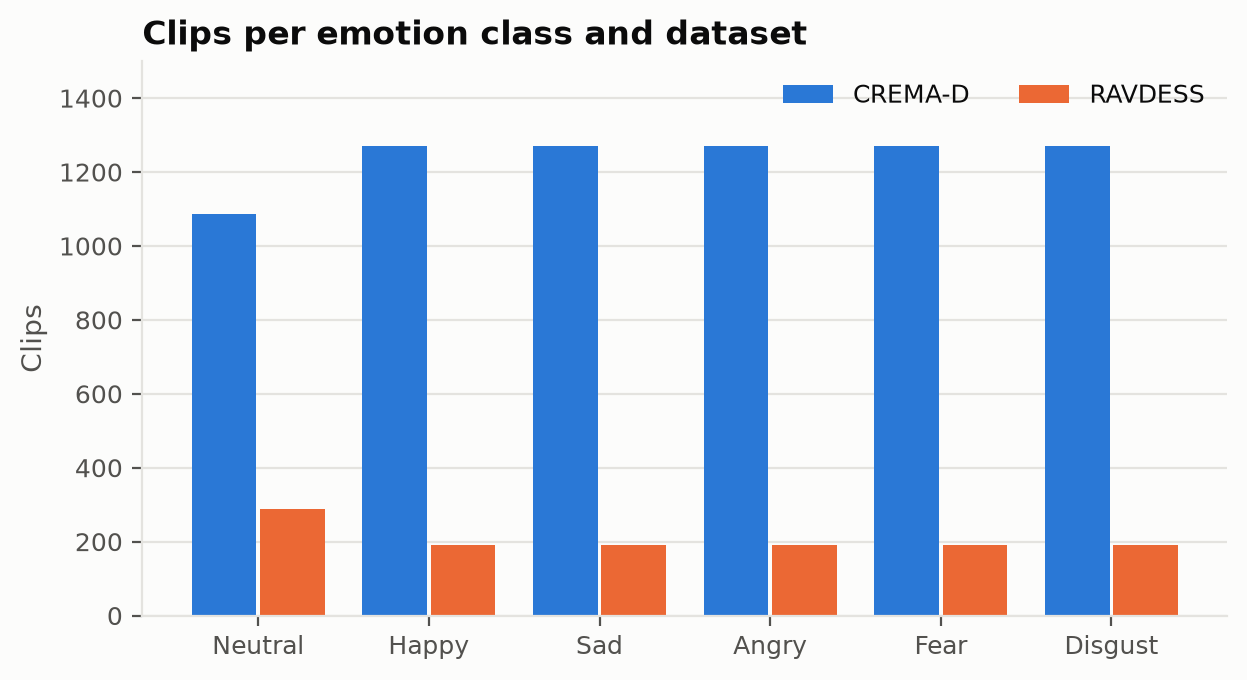

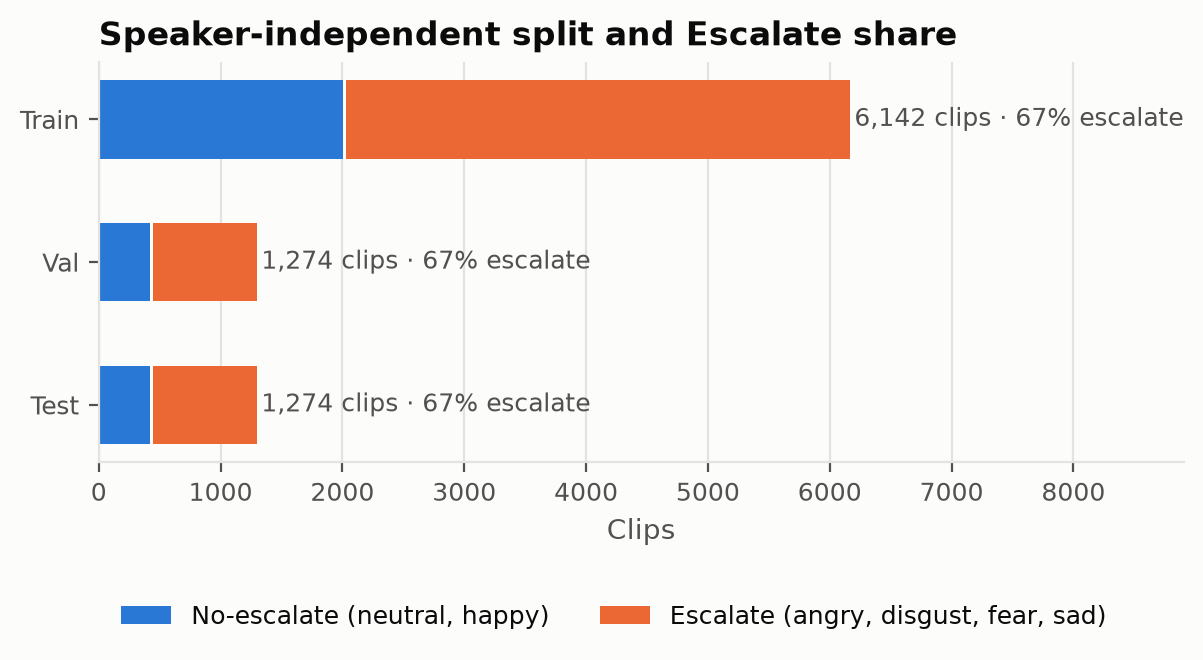

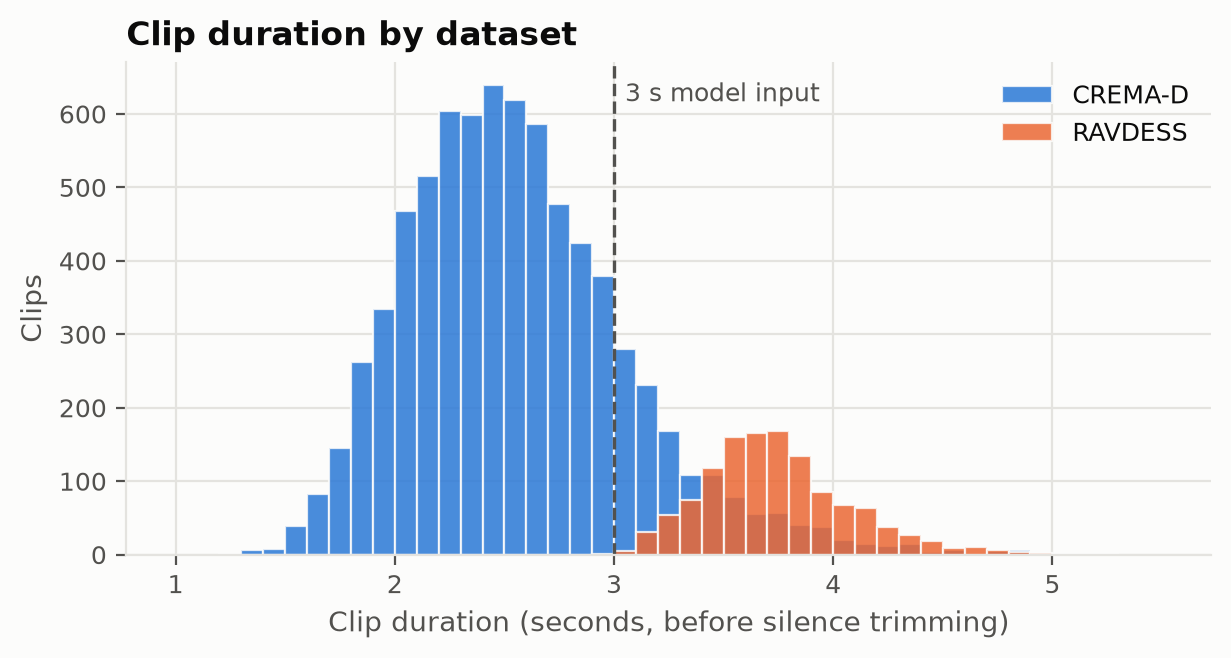

In [3]:
eda.class_distribution(meta); eda.escalate_by_split(meta); eda.duration_hist(meta)
show("01_class_distribution.png", 700)
show("02_split_escalate.png", 700)
show("03_duration_hist.png", 700)

**Observations**
* The classes are almost balanced (neutral is slightly smaller), so macro-F1 and accuracy tell a similar story.
* **67% of clips are Escalate.** A useless rule that flags every call would score 100% Escalate recall at 67%
  precision. Every escalation result below is compared against this "flag every call" reference.

<a id="4"></a>
## 4. Audio pre-processing and telephone-channel simulation

Every clip goes through the same pipeline (`src/preprocess.py`):

| # | Operation | Why |
|---|---|---|
| 1 | Resample to **16 kHz mono** | Common format; RAVDESS is 48 kHz and 5 clips are stereo |
| 2 | **Silence trimming** with a threshold set from each clip's own noise floor | CREMA-D background noise is only about 25 dB below the speech, so a fixed threshold trims nothing |
| 3 | **RMS loudness normalisation** to −23 dBFS (peak-limited at 0.99) | Removes recording-gain differences; the model must rely on pitch, timbre and dynamics, not absolute volume |
| 4 | **Centre-crop or zero-pad to 3 s** | Fixed-size model input |
| 5 | **Telephone version**: 8 kHz, 300–3400 Hz band-pass, G.711 μ-law 8-bit, back to 16 kHz | Simulates the narrow-band channel of real support calls |

In [4]:
import preprocess, fig_preprocess

if RUN_ALL:
    preprocess.run()

idx = pd.read_csv(PROCESSED / "audio_index.csv")
clean = np.load(PROCESSED / "audio_clean.npy", mmap_mode="r")
phone = np.load(PROCESSED / "audio_phone.npy", mmap_mode="r")

checks = pd.DataFrame({
    "value": [f"{clean.shape[0]:,} × {clean.shape[1]:,} samples (float16), clean and phone",
              f"{idx.trimmed_sec.median():.2f} s",
              f"{(meta.duration - idx.trimmed_sec).groupby(meta.dataset).median().round(2).to_dict()}",
              f"{(idx.trimmed_sec > 3).mean():.1%}",
              f"{sum(np.abs(clean[i]).max() >= 0.99 for i in range(len(clean)))} clips"]},
    index=["Processed arrays", "Median speech length after trimming", "Median silence removed (s)",
           "Clips longer than 3 s (centre-cropped)", "Clips reaching the peak limiter"])
display(checks)

,value
Processed arrays,"8,690 × 48,000 samples (float16), clean and phone"
Median speech length after trimming,1.60 s
Median silence removed (s),"{'CREMA-D': 0.96, 'RAVDESS': 1.81}"
Clips longer than 3 s (centre-cropped),4.0%
Clips reaching the peak limiter,28 clips


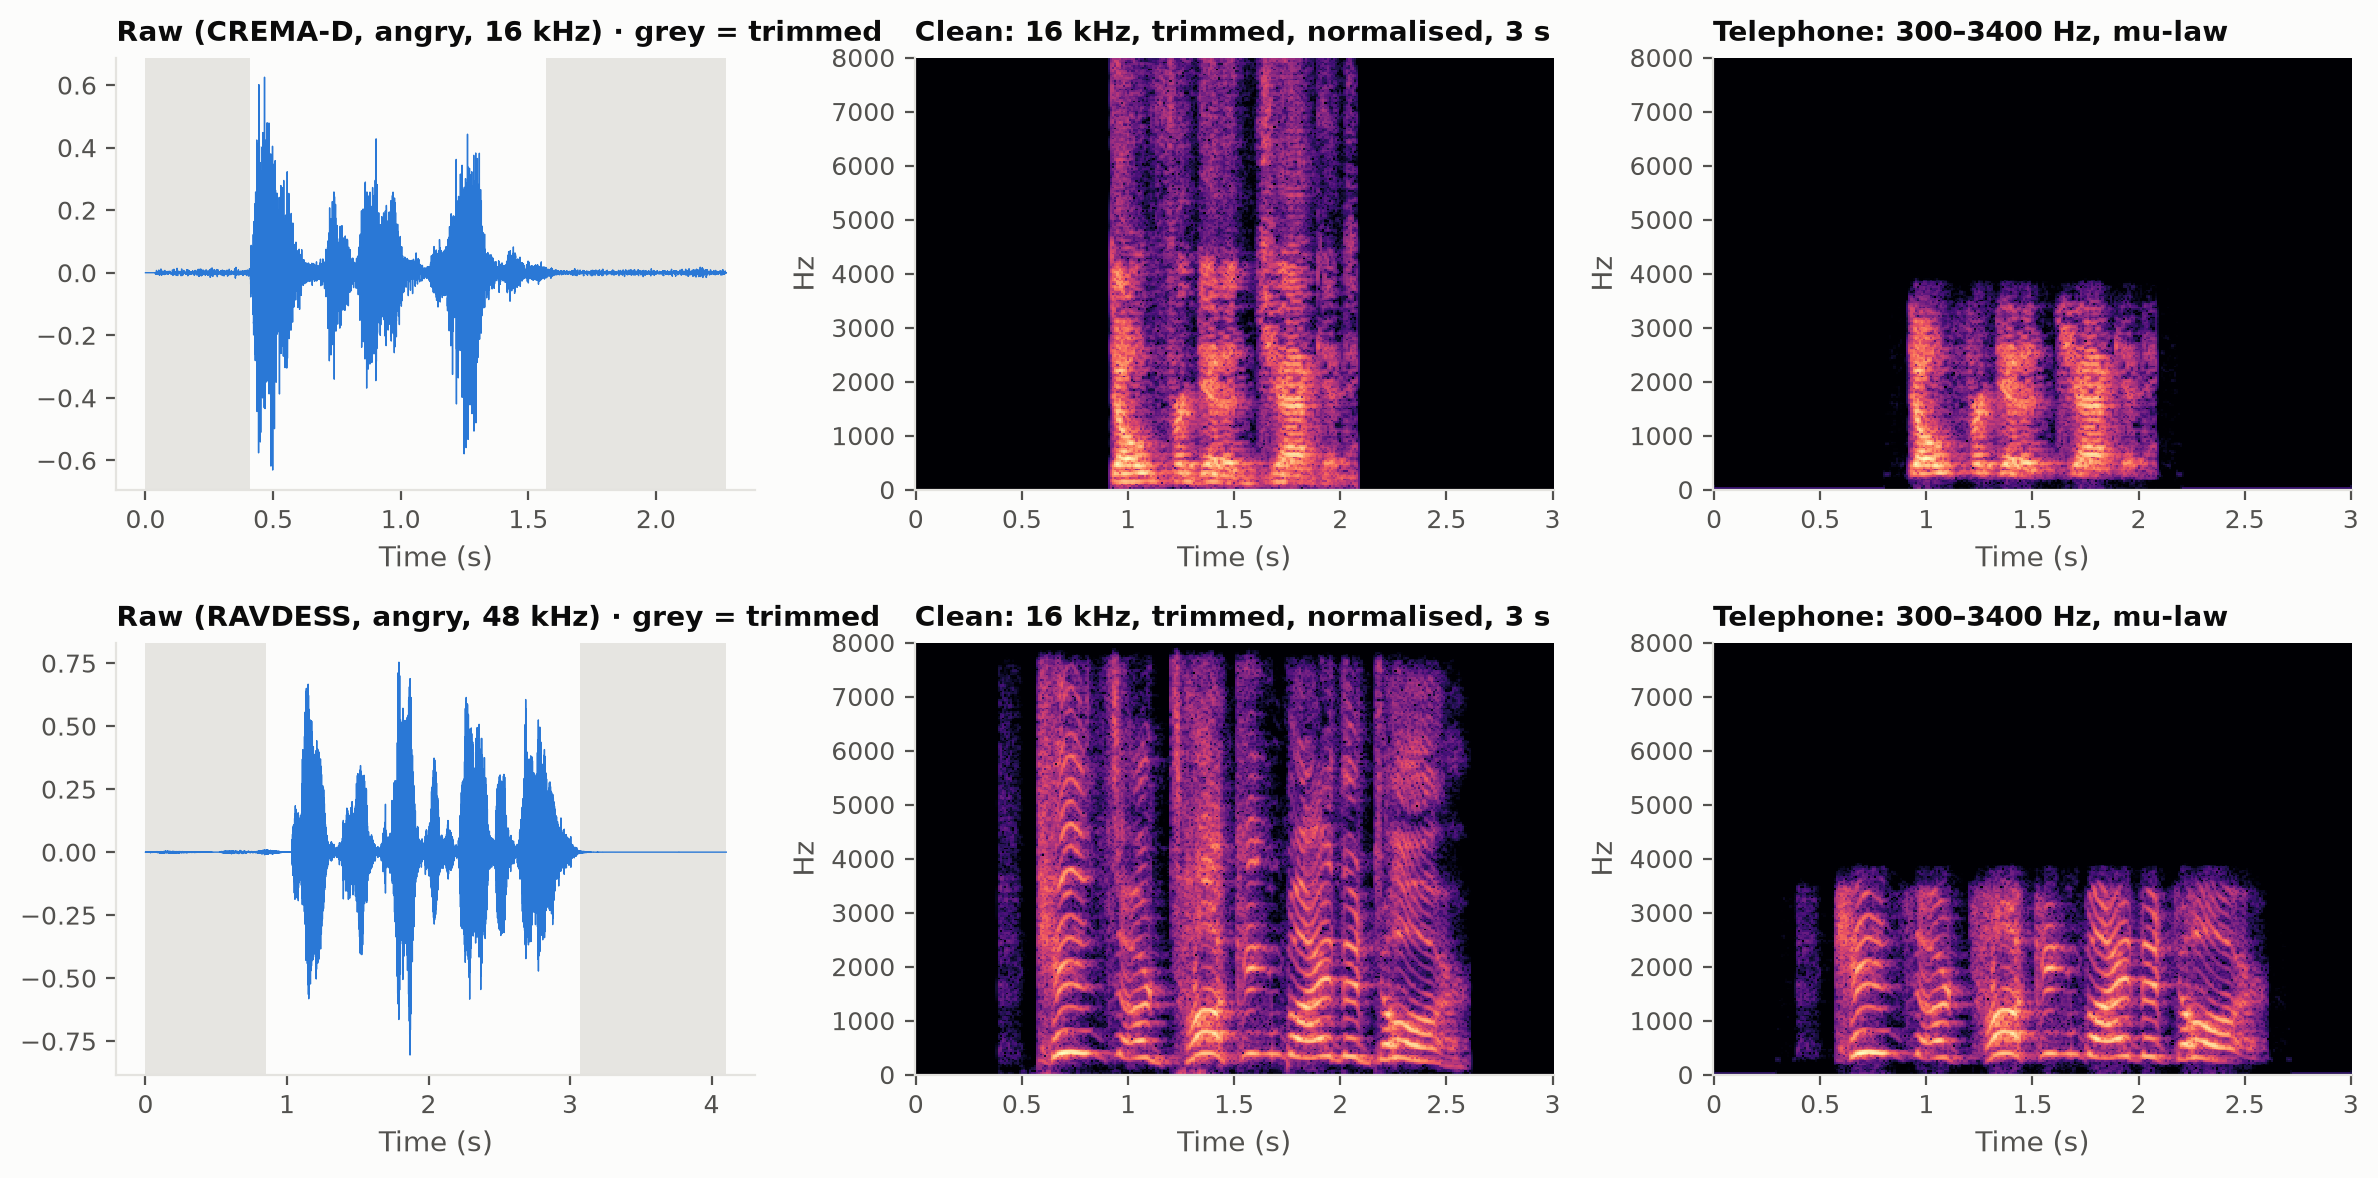

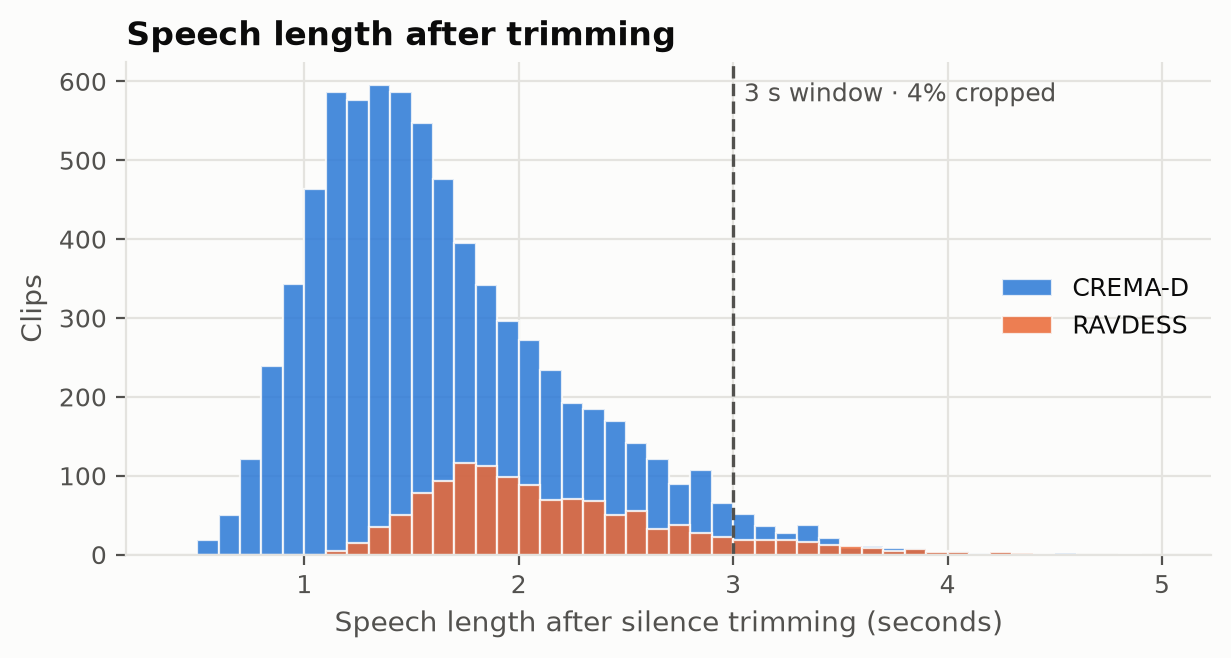

Listen: the same angry utterance, clean vs telephone channel


In [5]:
if RUN_ALL:
    fig_preprocess.main()
show("04_preprocessing_before_after.png", 1000)
show("05_trimmed_length_hist.png", 650)

print("Listen: the same angry utterance, clean vs telephone channel")
ex = RESULTS / "audio_examples"
display(Audio(filename=str(ex / "CREMA-D_angry_CRE_1001_clean.wav")))
display(Audio(filename=str(ex / "CREMA-D_angry_CRE_1001_phone.wav")))

**Observations**
* Adaptive trimming removes about 1 s of edge silence from CREMA-D clips (a fixed 30 dB threshold removed
  nothing) and cuts the share of cropped clips from 12% to 4%.
* The telephone version keeps 0.002% of its energy above 3.6 kHz (clean audio: 2.1%), so the band-pass works.

<a id="5"></a>
## 5. Feature extraction

Two representations (`src/features.py`):

**A. Handcrafted features for the baselines: 259 per clip**, computed on the speech region only (padding excluded):

| Family | Features | Count |
|---|---|---|
| MFCC | 40 coefficients + Δ + ΔΔ, each summarised by mean and std | 240 |
| Pitch (pYIN) | F0 mean, std, 5th / 95th percentile, range | 5 |
| Voicing | fraction of voiced frames | 1 |
| Energy | RMS in dB: mean, std, 95th percentile | 3 |
| Spectral | ZCR, centroid, roll-off, bandwidth, flatness (mean, std) | 10 |

**B. Log-mel spectrograms for the CNN:** 64 mel bands × 301 frames (25 ms window, 10 ms hop, 3 s), computed with
the same `torchaudio` transform the CNN uses during training.

No scaler is fitted here; scaling and imputation are fitted on the training split only, inside each model.

In [6]:
import features, fig_features

if RUN_ALL:
    for v in features.VERSIONS:
        features.extract_logmel(v)
        features.extract_handcrafted(v)

hc_clean = pd.read_csv(PROCESSED / "handcrafted_clean.csv").drop(columns="path")
hc_phone = pd.read_csv(PROCESSED / "handcrafted_phone.csv").drop(columns="path")
logmel = np.load(PROCESSED / "logmel_clean.npy", mmap_mode="r")
print(f"Handcrafted: {hc_clean.shape} per version · log-mel: {logmel.shape} per version")
print(f"Clips with no reliable pitch (pYIN found < 3 voiced frames): clean {hc_clean.f0_mean.isna().sum()}, "
      f"phone {hc_phone.f0_mean.isna().sum()} → filled with the training median inside the model pipeline")

display(Markdown("**Median value of key cues per emotion (training set, clean audio)**"))
display(pd.read_csv(RESULTS / "feature_medians_by_emotion.csv", index_col=0))
display(Markdown("**How the telephone channel shifts the same cues (all clips, median)**"))
display(pd.read_csv(RESULTS / "feature_shift_clean_vs_phone.csv", index_col=0))

Handcrafted: (8690, 259) per version · log-mel: (8690, 64, 301) per version
Clips with no reliable pitch (pYIN found < 3 voiced frames): clean 525, phone 250 → filled with the training median inside the model pipeline


**Median value of key cues per emotion (training set, clean audio)**

,f0_mean,f0_std,rms_db_std,centroid_mean,voiced_frac,zcr_mean
emotion,,,,,,
neutral,159.34,19.02,5.98,1330.14,0.70,0.09
happy,223.07,33.88,6.63,1431.27,0.73,0.10
sad,168.51,15.62,5.19,1271.55,0.45,0.07
angry,229.65,31.52,8.34,1665.00,0.72,0.12
fear,214.93,22.27,6.10,1430.79,0.73,0.09
disgust,177.68,21.30,6.02,1434.33,0.52,0.10


**How the telephone channel shifts the same cues (all clips, median)**

,clean_median,phone_median
f0_mean,194.12,263.73
f0_std,23.12,36.08
rms_db_std,6.30,8.74
centroid_mean,1416.27,1058.78
voiced_frac,0.67,0.54
zcr_mean,0.10,0.09


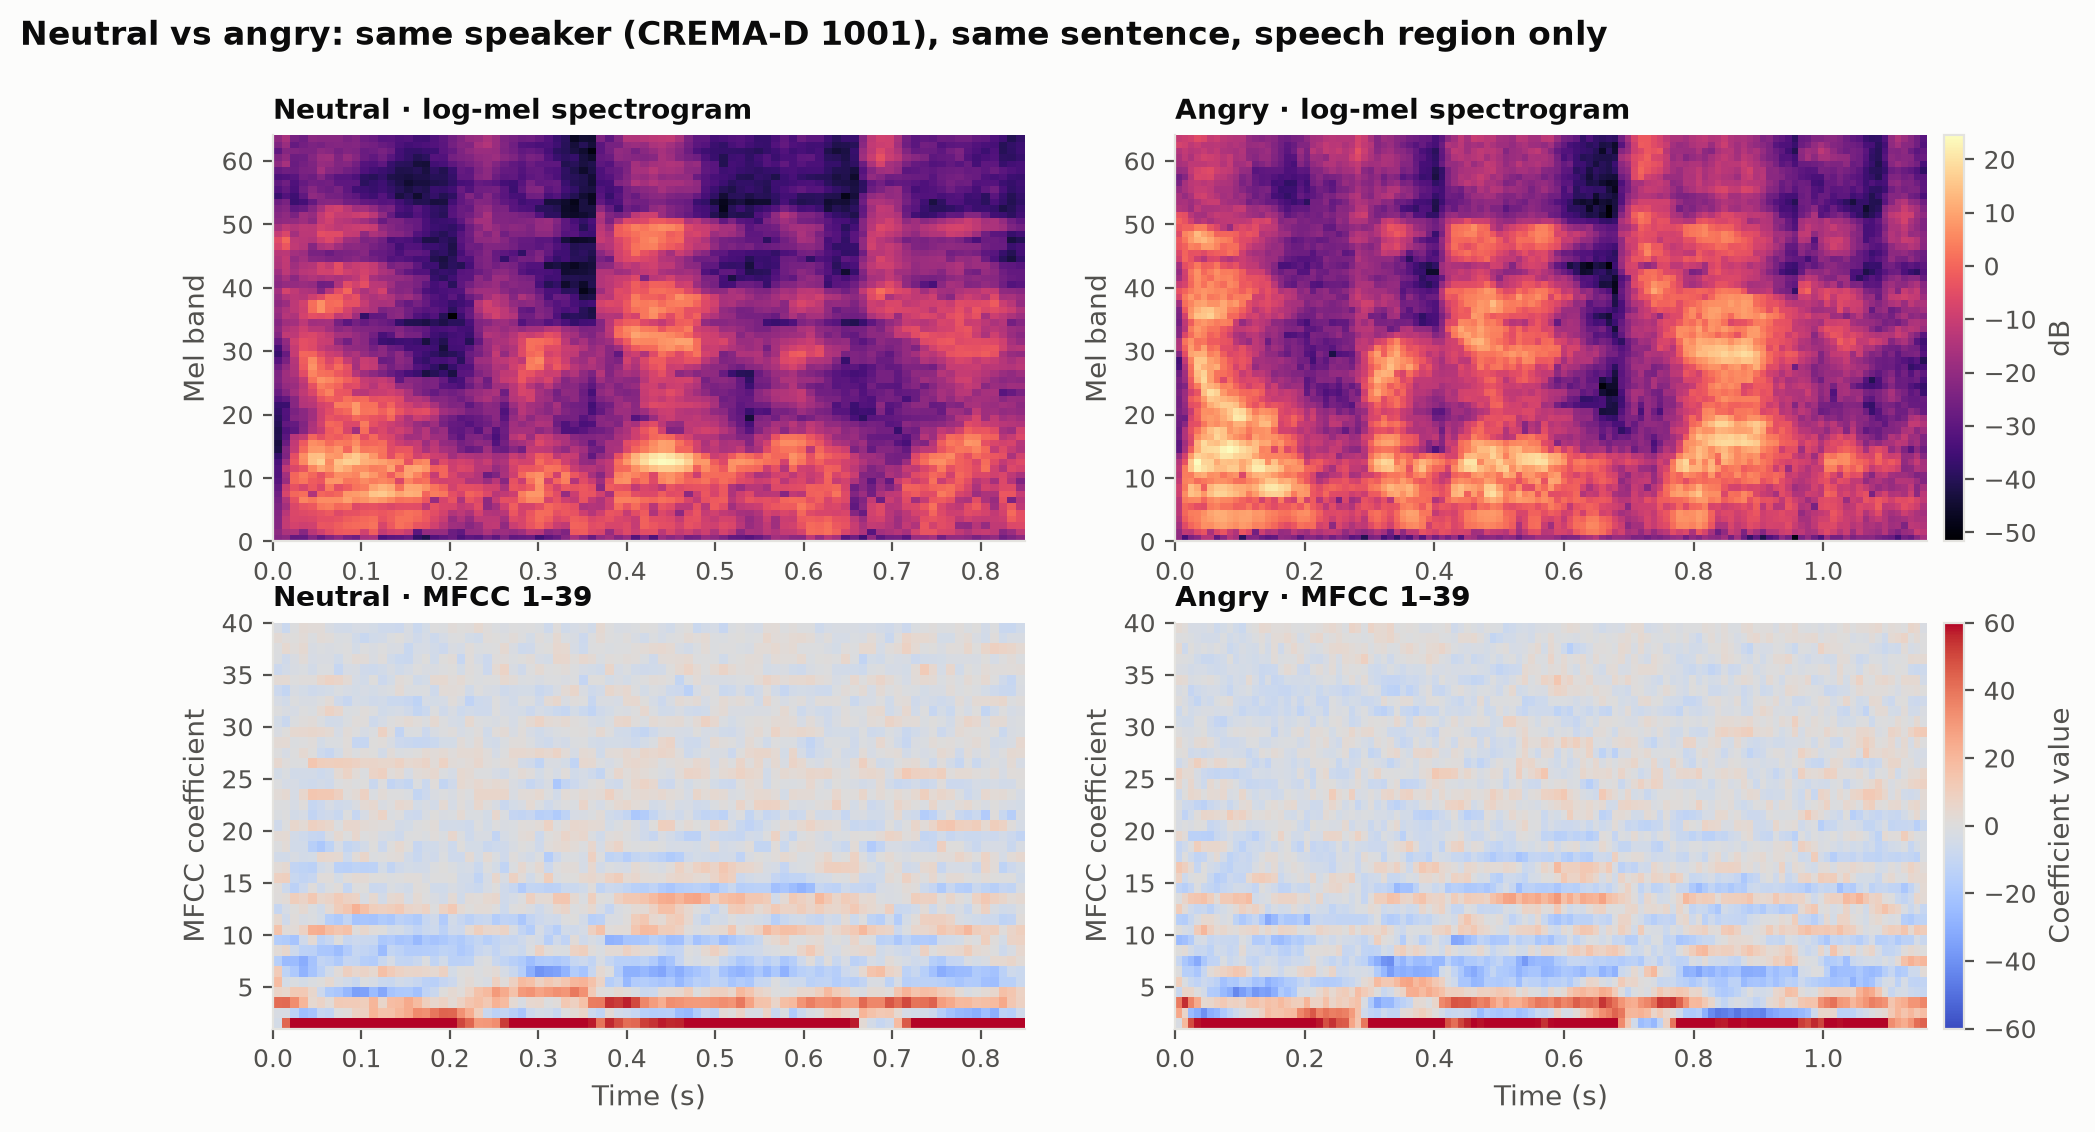

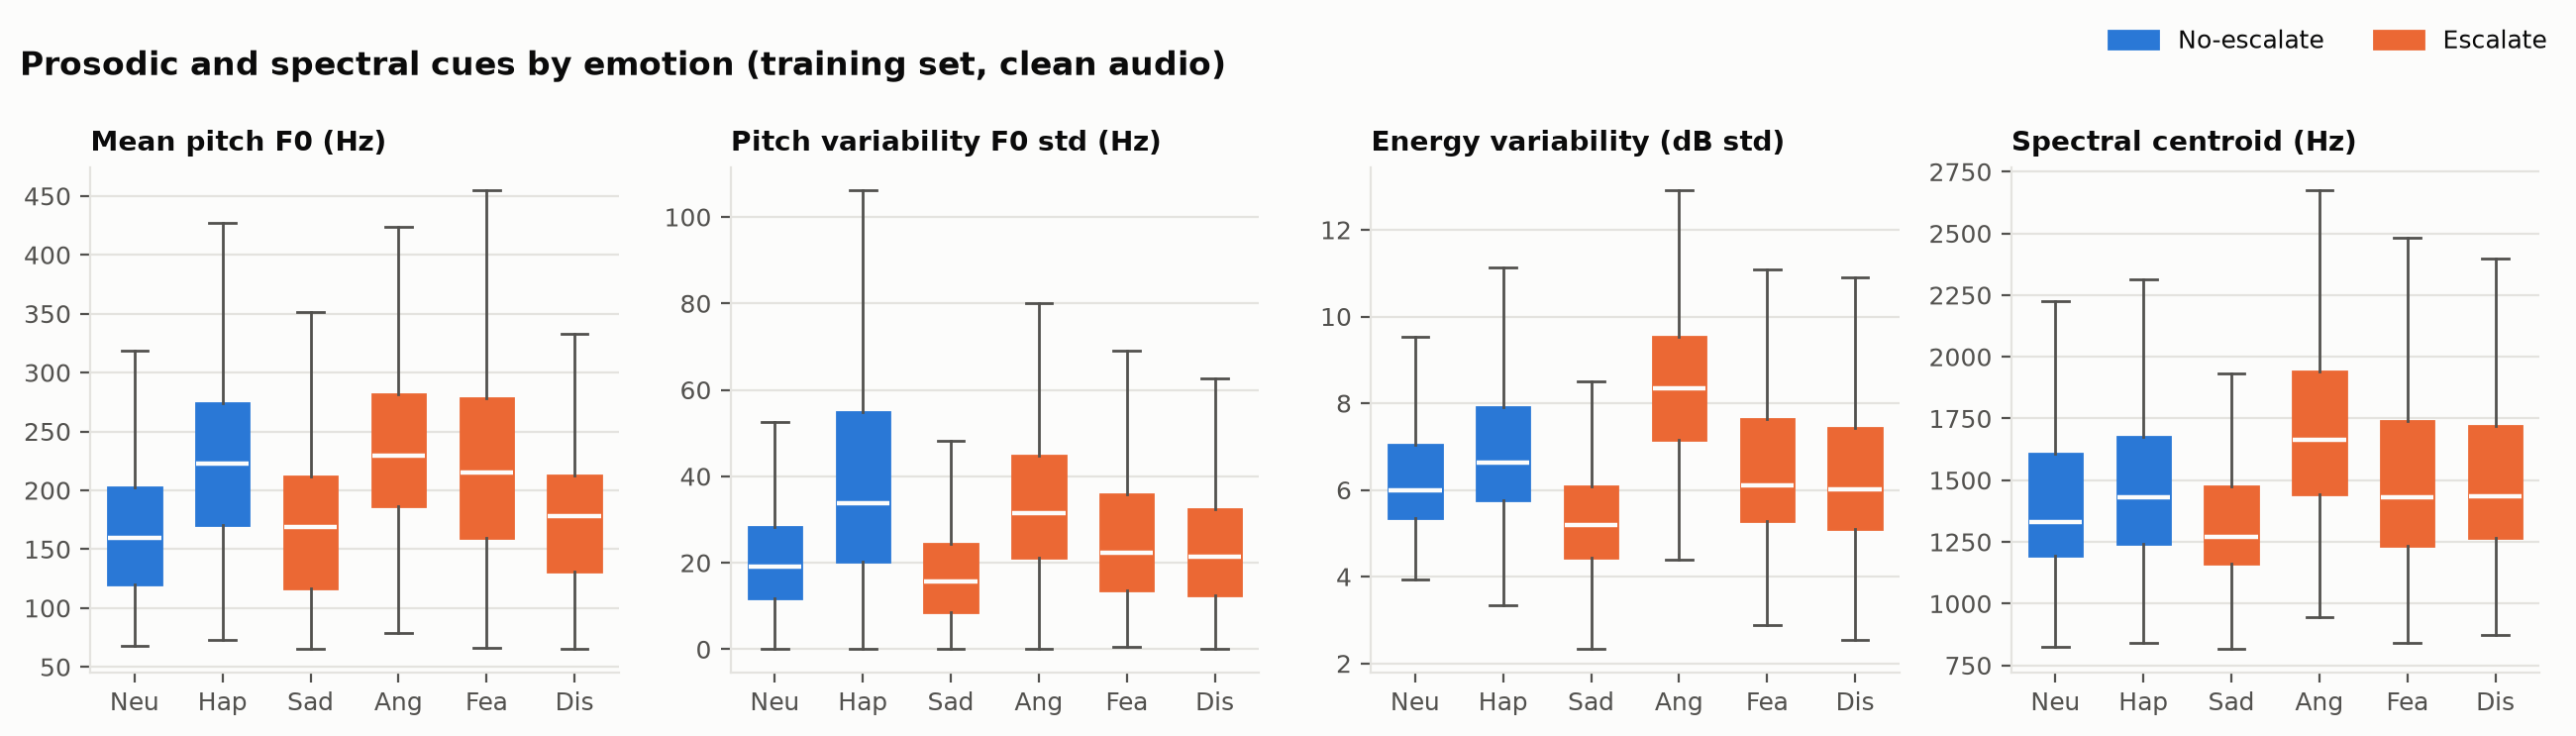

In [7]:
if RUN_ALL:
    fig_features.main()
show("06_angry_vs_neutral_features.png", 1000)
show("07_feature_boxplots.png", 1100)

**Observations**
* **Angry** stands out clearly: highest pitch (230 Hz), largest energy variation and brightest spectrum.
  **Sad** is the opposite: low pitch, flat energy, least voiced.
* **Happy overlaps angry** in pitch and pitch variability. This predicts the costly *angry → happy* confusion,
  because happy is No-escalate.
* **The telephone channel corrupts pitch.** Median F0 jumps from 194 to 264 Hz: the 300 Hz high-pass removes the
  fundamental of most voices, and the pitch tracker locks onto a harmonic. A model trained on clean audio is
  systematically misled on phone calls (confirmed in Section 6).
* The 525 clips without pitch are quiet, noisy recordings (median SNR 13.6 dB vs 24.5 dB) of mostly sad or
  disgusted speech. This is a property of the data, not an extraction bug.

<a id="6"></a>
## 6. Baseline models: SVM and Random Forest

* Pipeline: median imputation → standardisation (SVM only) → classifier, all fitted on the training split.
* Hyper-parameters chosen by **5-fold cross-validation grouped by speaker** (`StratifiedGroupKFold`) on the training
  split, scored by macro-F1. Class weighting is balanced.
* Trained on **clean** audio and evaluated on **validation** clean and phone audio (the test set is kept for Section 8).

In [8]:
import baseline

if RUN_ALL:
    baseline.main()

m6 = load_json("metrics_step6_baseline.json")
rows = []
for k, name in [("svm", "SVM (RBF)"), ("rf", "Random Forest")]:
    r = m6[k]
    rows.append({"model": name, "best params": r["best_params"], "CV macro-F1": round(r["cv_macro_f1"], 3),
                 "val clean acc": round(r["clean"]["accuracy"], 3), "val clean F1": round(r["clean"]["macro_f1"], 3),
                 "val phone acc": round(r["phone"]["accuracy"], 3), "val phone F1": round(r["phone"]["macro_f1"], 3)})
display(pd.DataFrame(rows).set_index("model"))
display(Markdown("**Top SVM grid-search settings (speaker-grouped CV)**"))
display(pd.read_csv(RESULTS / "cv_svm.csv").head(5))

,best params,CV macro-F1,val clean acc,val clean F1,val phone acc,val phone F1
model,,,,,,
SVM (RBF),"{'clf__C': 3, 'clf__gamma': 0.002}",0.517,0.512,0.511,0.261,0.204
Random Forest,"{'clf__max_features': 0.15, 'clf__min_samples_...",0.476,0.480,0.470,0.358,0.351


**Top SVM grid-search settings (speaker-grouped CV)**

,params,mean_test_score,std_test_score
0,"{'clf__C': 3, 'clf__gamma': 0.002}",0.516804,0.014037
1,"{'clf__C': 3, 'clf__gamma': 0.004}",0.516352,0.016448
2,"{'clf__C': 1, 'clf__gamma': 0.004}",0.510898,0.013385
3,"{'clf__C': 10, 'clf__gamma': 0.001}",0.509656,0.016693
4,"{'clf__C': 3, 'clf__gamma': 0.001}",0.509514,0.014355


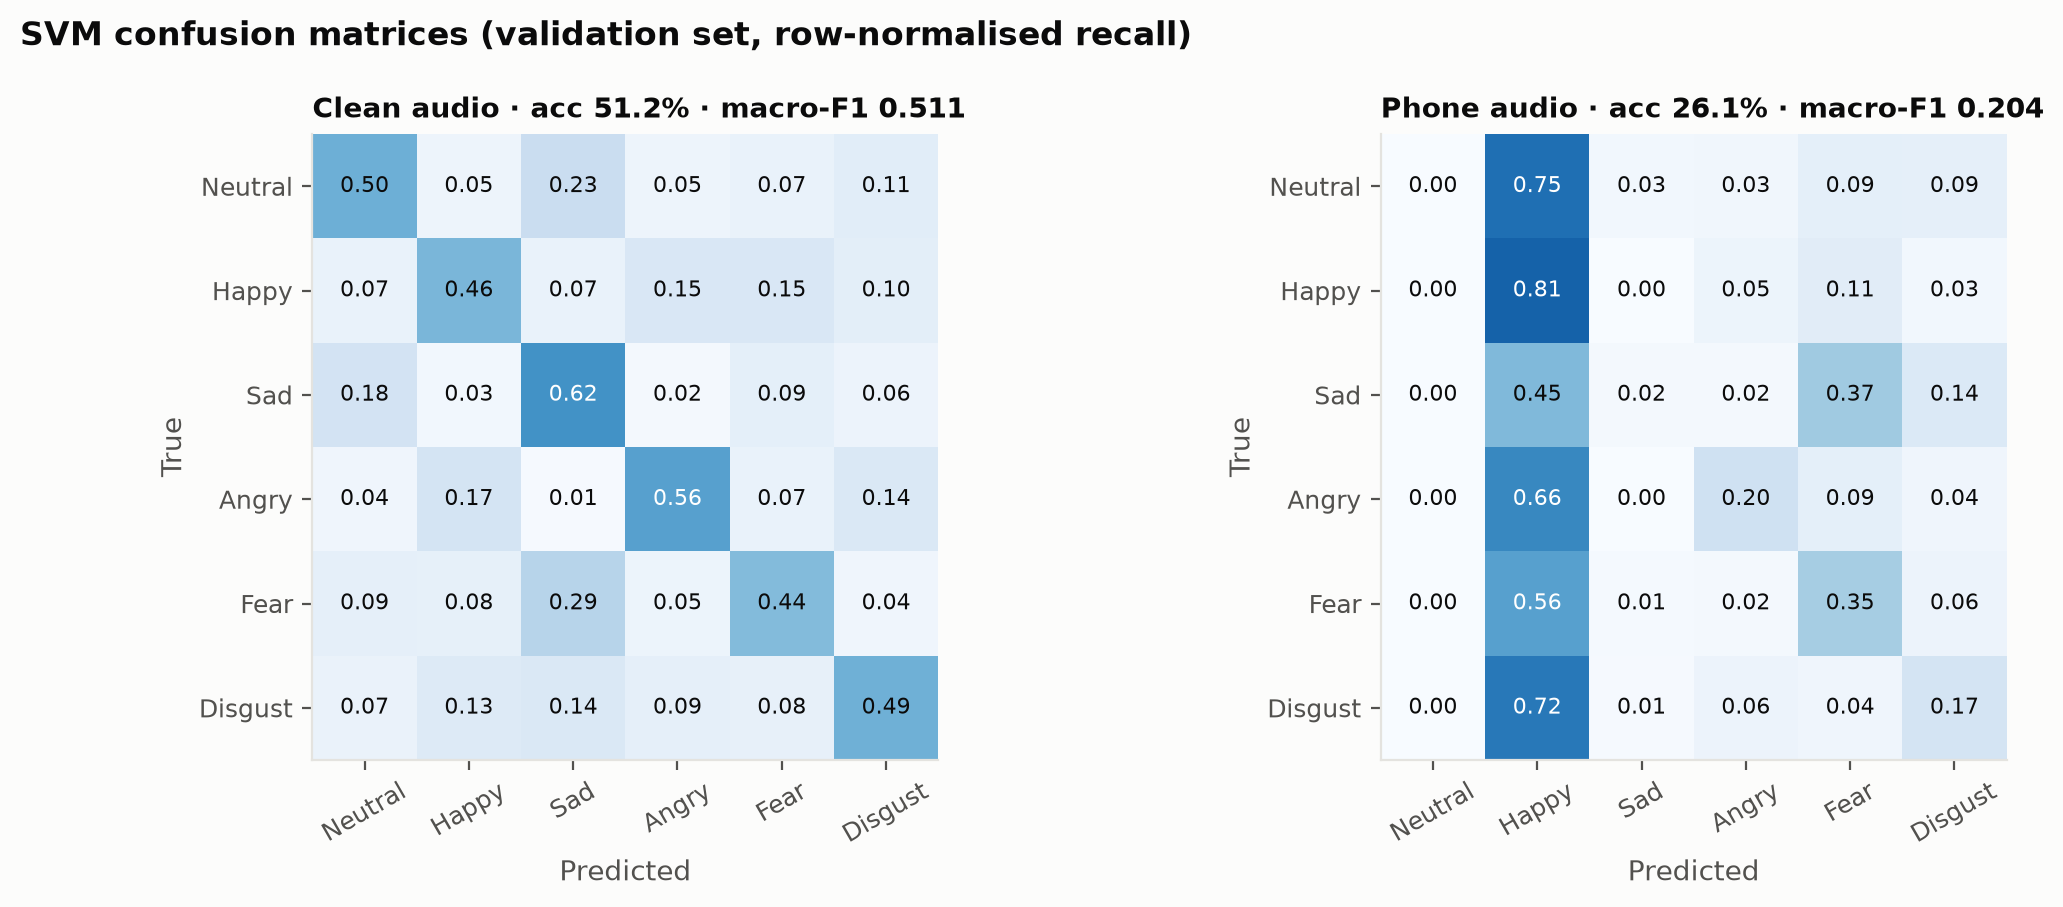

In [9]:
show("08_confusion_svm_val.png", 1000)

**Observations**
* The SVM reaches **51% accuracy on clean audio** (chance about 17%) on speakers it has never heard.
* **On telephone audio it collapses to 26%**: it predicts *happy* for most clips, including 66% of angry ones. This
  is the pitch-doubling effect from Section 5. Deployed on real calls, this model would miss most angry customers.

<a id="7"></a>
## 7. Deep learning: CNN and CNN + BiLSTM

**Architectures** (`src/train_cnn.py`)
* **CNN (1.18 M parameters):** 4 blocks of [Conv3×3 → BN → ReLU] × 2 → MaxPool → Dropout, channels 32/64/128/256;
  mean over frequency, then mean + max pooling over time, then a linear layer for 6 classes.
* **CNN + BiLSTM (1.47 M parameters):** 3 conv blocks → bidirectional LSTM (128 units) over time → mean + max
  pooling → linear.

**Training**
* On-the-fly augmentation on the GPU: **telephone channel** (50% of clips), **white noise** at 10–20 dB SNR (50%),
  **random time shift** (50%) and **SpecAugment** (2 frequency masks up to 8 bands, 2 time masks up to 30 frames).
* AdamW (learning rate 1e-3, weight decay 1e-2) with a one-cycle schedule, 60 epochs, batch 64, label smoothing 0.05,
  class-weighted loss, bfloat16 mixed precision.
* Model selection: the epoch with the best **mean validation macro-F1 over clean and phone audio**.

In [10]:
import train_cnn

model = train_cnn.CNN()
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

CNN(
  (blocks): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.1, inplace=False)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=Fal

In [11]:
if RUN_ALL:
    for arch, seed in [("cnn", 42), ("crnn", 42), ("cnn", 7), ("cnn", 123)]:
        train_cnn.main(arch, seed)

rows = []
for name in ["cnn_s42", "cnn_s7", "cnn_s123", "crnn_s42"]:
    r = load_json(f"metrics_step7_{name}.json")
    rows.append({"model": name, "params (M)": round(r["params"] / 1e6, 2), "best epoch": r["best_epoch"],
                 "val clean acc": round(r["clean"]["accuracy"], 3), "val clean F1": round(r["clean"]["macro_f1"], 3),
                 "val phone acc": round(r["phone"]["accuracy"], 3), "val phone F1": round(r["phone"]["macro_f1"], 3),
                 "train time (s)": r["train_seconds"]})
display(pd.DataFrame(rows).set_index("model"))

,params (M),best epoch,val clean acc,val clean F1,val phone acc,val phone F1,train time (s)
model,,,,,,,
cnn_s42,1.18,60,0.633,0.632,0.620,0.619,1293.3
cnn_s7,1.18,60,0.618,0.616,0.608,0.608,465.1
cnn_s123,1.18,56,0.608,0.608,0.604,0.604,368.7
crnn_s42,1.47,56,0.633,0.634,0.600,0.599,437.6


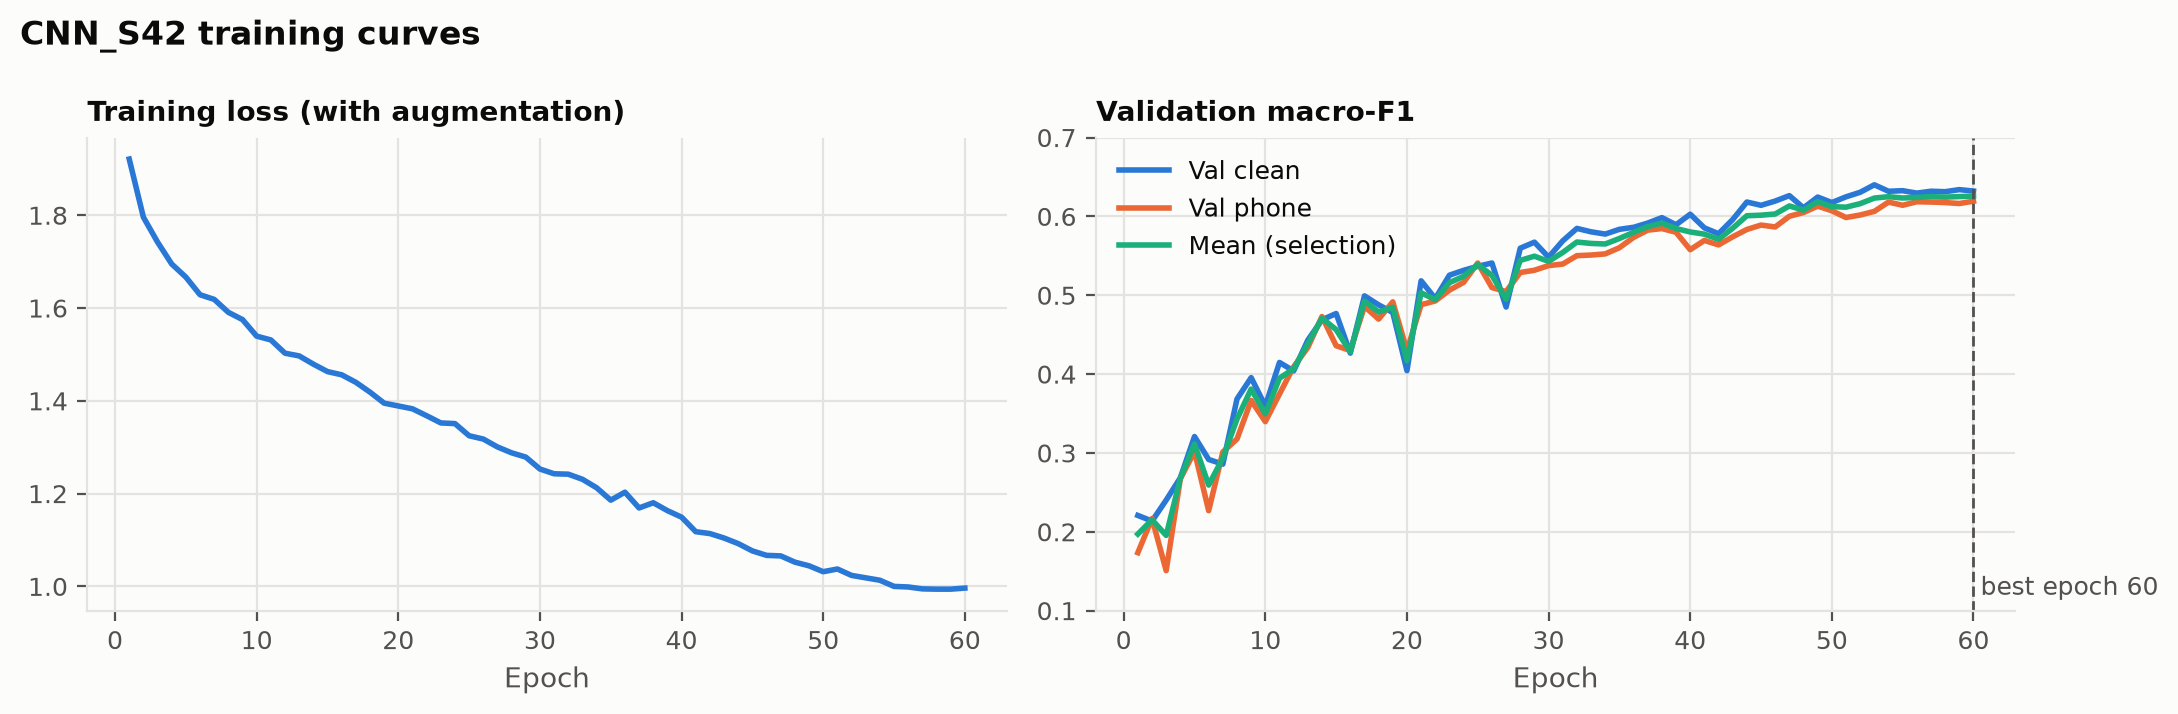

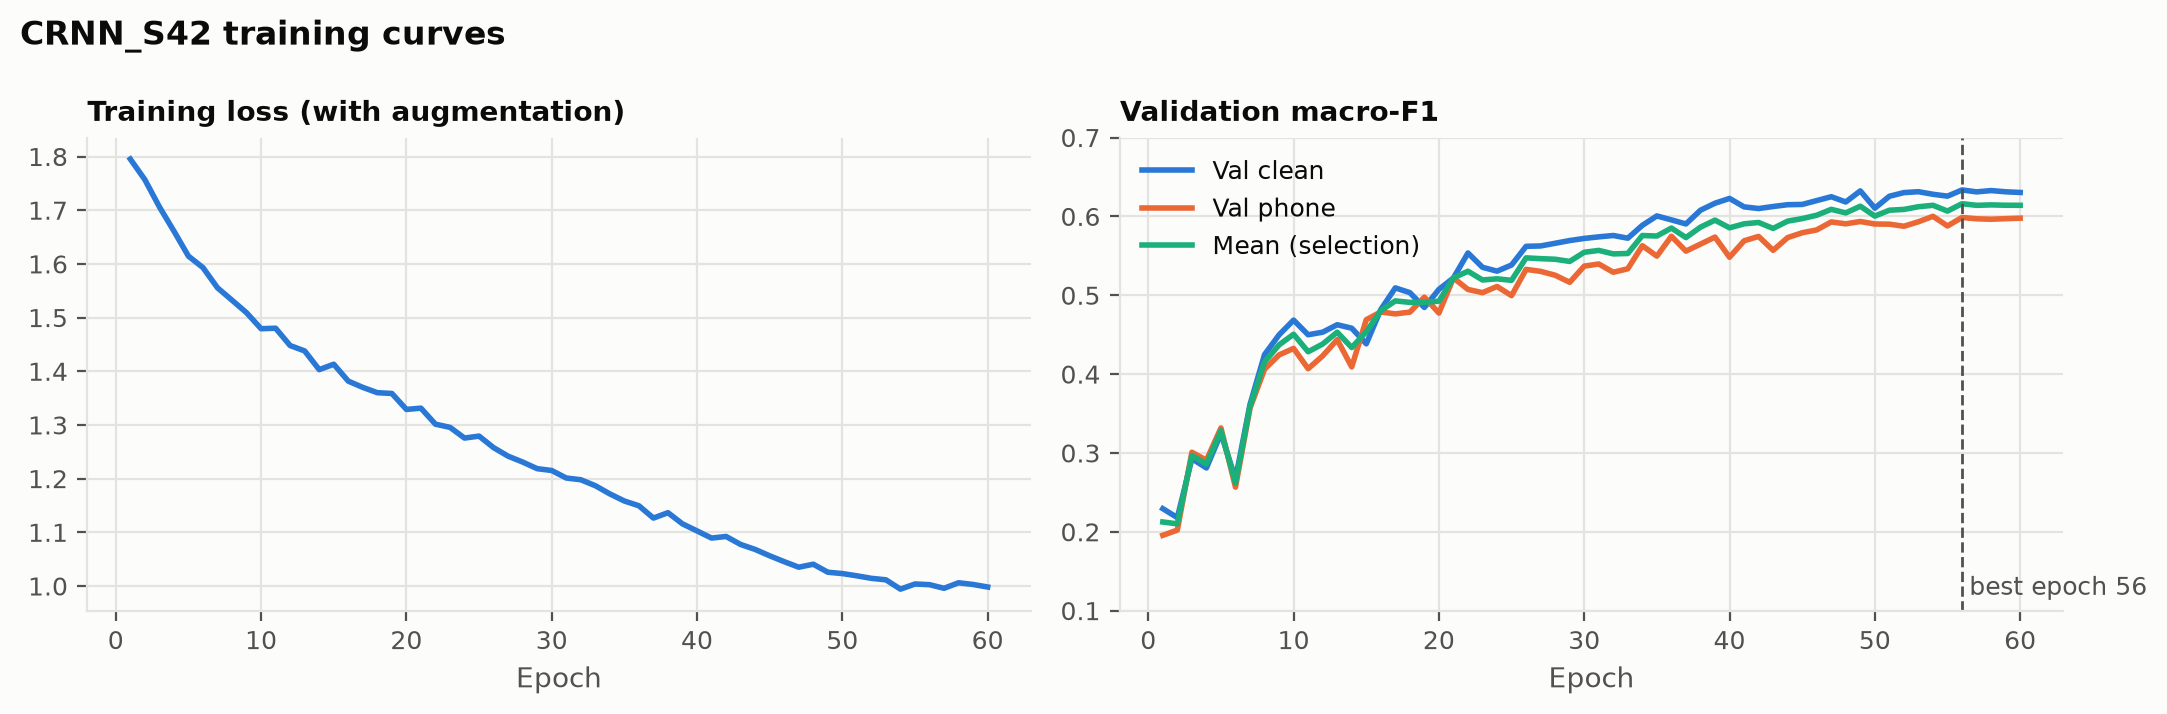

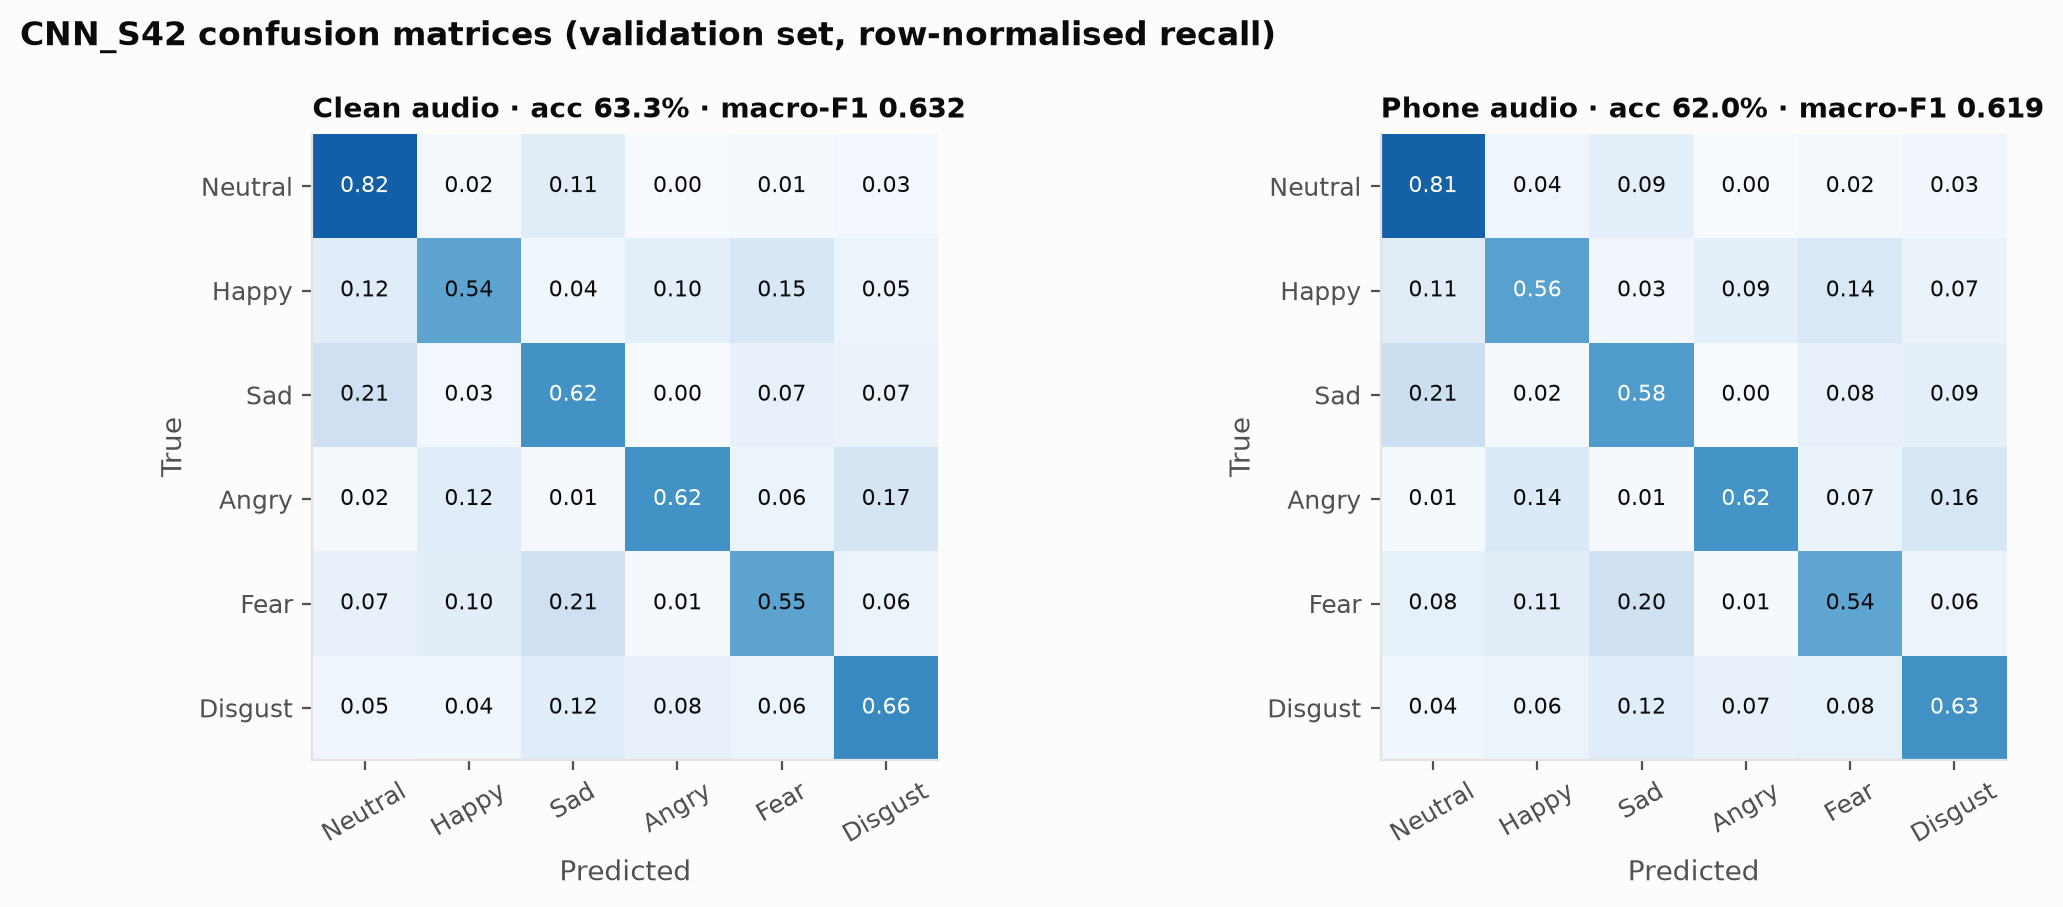

In [12]:
show("09_training_curves_cnn_s42.png", 1000)
show("09_training_curves_crnn_s42.png", 1000)
show("08_confusion_cnn_s42_val.png", 1000)

**Observations**
* Training takes about 6–8 minutes per model on the RTX 5060. The cnn_s42 time (1,293 s) includes a pause of
  about 10 minutes when the laptop suspended work; training itself was not affected.
* Training is stable: the loss falls steadily and validation macro-F1 rises to about 0.63 with no overfitting.
* The **validation gap between clean and phone audio shrinks from 0.31 (SVM) to 0.013 (CNN)**: the augmentation
  makes the model robust to the telephone channel.
* The CNN + BiLSTM is no better than the plain CNN despite having 25% more parameters, so the **CNN is the final
  model**.

<a id="8"></a>
## 8. Held-out test evaluation

The test split (1,274 clips, **17 speakers never used for training or tuning**) is evaluated once, for all models,
on clean and telephone audio.
* **CNN robustness:** trained with 3 random seeds (42, 7, 123), reported as mean ± std. Seed 42 was fixed in advance
  as the final model.
* **Fairer baseline:** a **multi-condition SVM** trained on clean + telephone training features (same
  hyper-parameters as Section 6), to separate the effect of the training data from the effect of the architecture.

In [13]:
import evaluate

if RUN_ALL:
    baseline.train_multicondition()
    evaluate.main()

test = pd.read_csv(RESULTS / "test_results.csv")
view = test.assign(
    accuracy=test.accuracy.map("{:.3f}".format),
    macro_f1=test.apply(lambda r: f"{r.macro_f1:.3f}" + (f" ± {r.macro_f1_std:.3f}" if pd.notna(r.macro_f1_std) else ""), axis=1))
display(view.pivot(index="model", columns="audio", values=["accuracy", "macro_f1"])
            .reindex(["SVM (clean-trained)", "Random Forest", "SVM (multi-condition)", "CNN (3 seeds)", "CNN + BiLSTM"]))

accuracy              macro_f1               
audio                    clean  phone          clean          phone
model                                                              
SVM (clean-trained)      0.545  0.264          0.542          0.209
Random Forest            0.533  0.385          0.516          0.367
SVM (multi-condition)    0.535  0.523          0.533          0.519
CNN (3 seeds)            0.654  0.641  0.654 ± 0.010  0.642 ± 0.003
CNN + BiLSTM             0.628  0.608          0.628          0.606

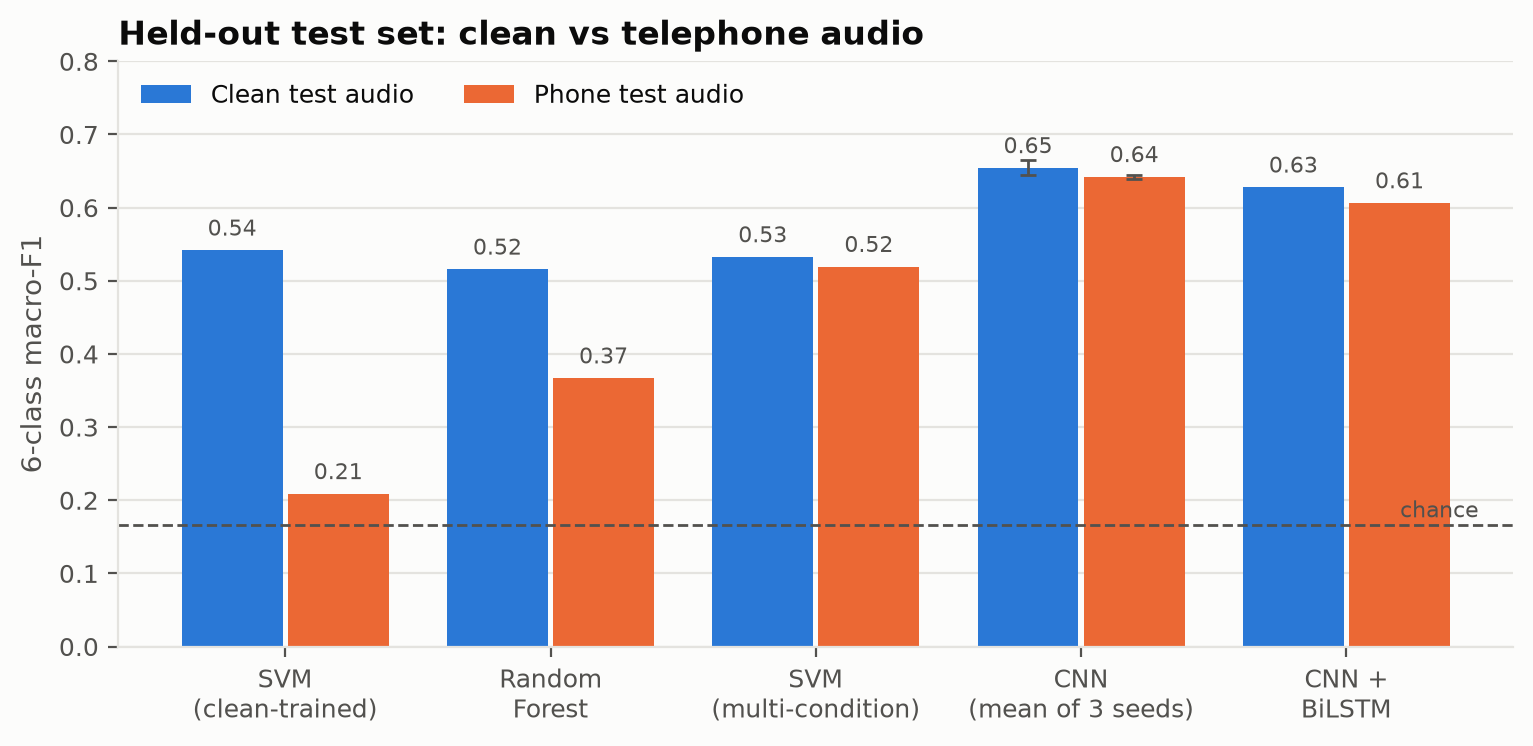

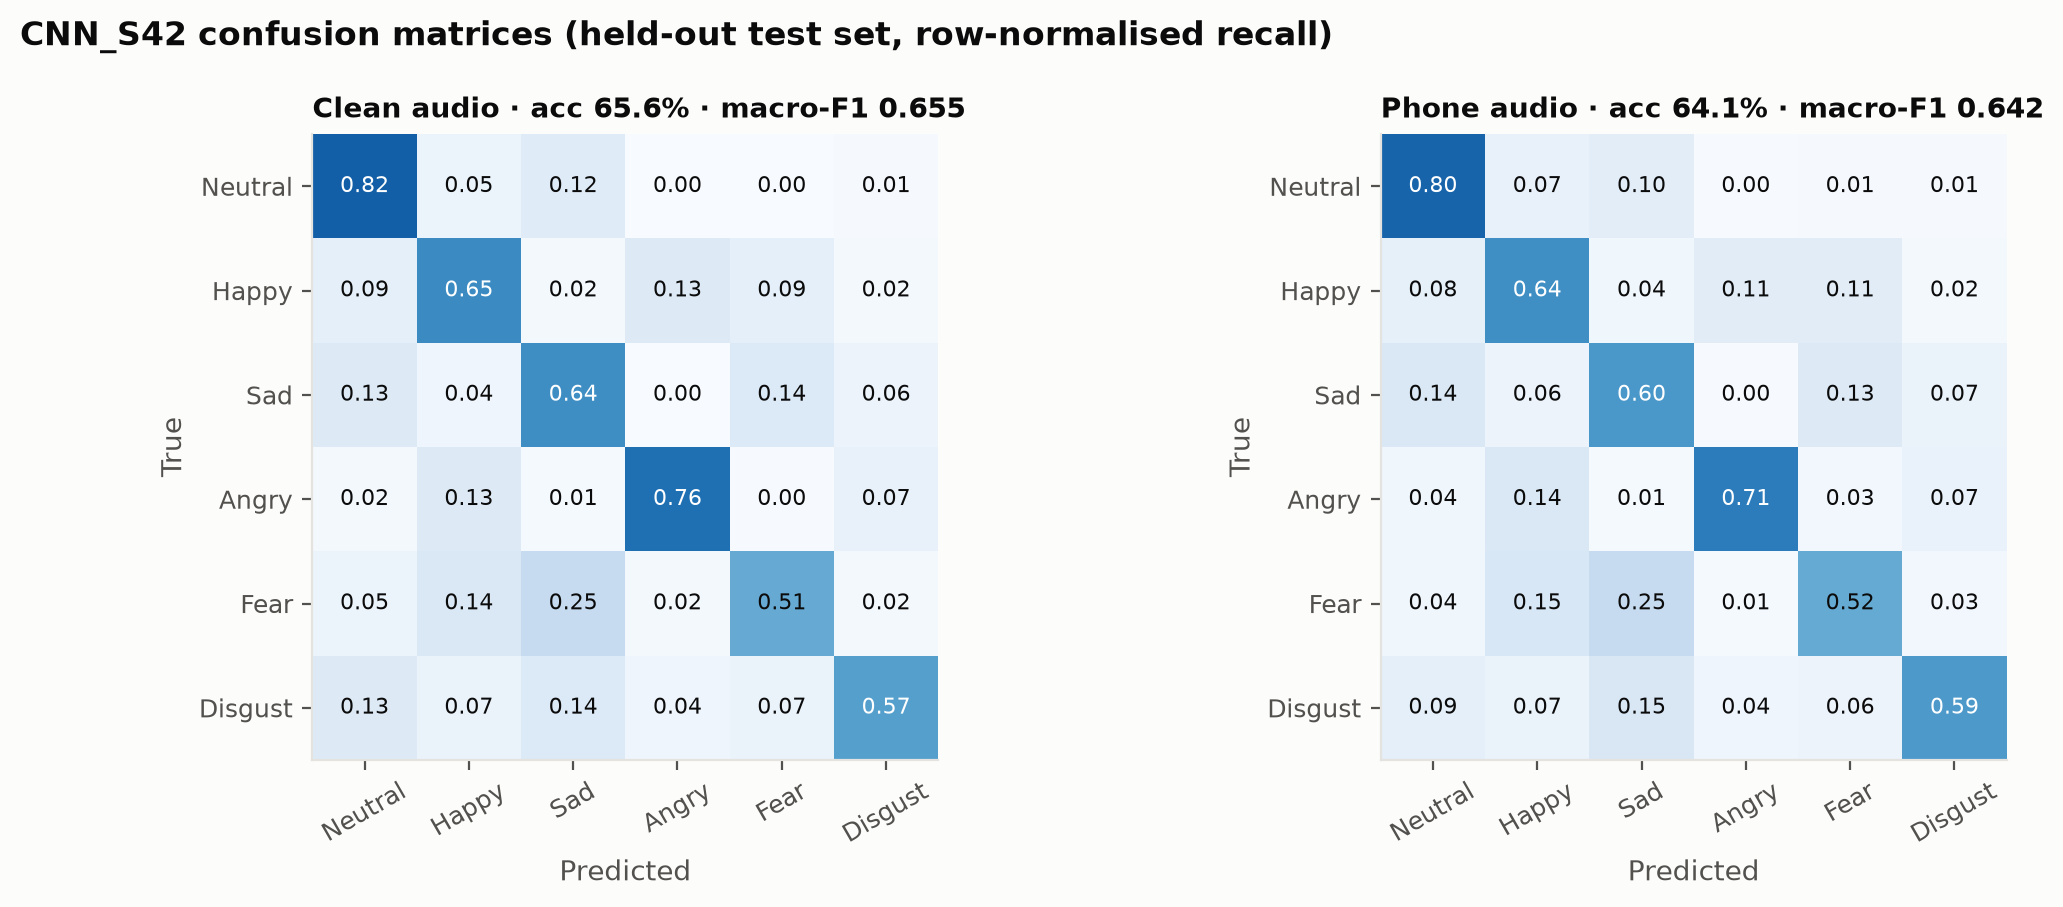

**Final CNN (seed 42), per-class recall on the test set**

,neutral,happy,sad,angry,fear,disgust
clean,0.82,0.65,0.64,0.76,0.51,0.57
phone,0.80,0.64,0.60,0.71,0.52,0.59


In [14]:
show("10_model_comparison_test.png", 900)
show("11_confusion_cnn_s42_test.png", 1000)

final = load_json("metrics_step8_test.json")["cnn_s42"]
display(Markdown("**Final CNN (seed 42), per-class recall on the test set**"))
display(pd.DataFrame({v: final[v]["per_class_recall"] for v in ("clean", "phone")}).T.round(2))

**Observations**
* **CNN test macro-F1: 0.654 ± 0.010 (clean) and 0.642 ± 0.003 (phone).** Test scores are slightly *above*
  validation, and the 3 seeds agree closely, so the result is stable and not over-tuned.
* **Where the gain comes from (phone audio):** clean-trained SVM 0.21 → multi-condition SVM 0.52 (**+0.31 from
  matching the training data to the channel**) → CNN 0.64 (**+0.12 from learned spectro-temporal features**).
* **Remaining errors:** *fear → sad* (25%) and *sad → neutral* (14%) among low-energy emotions; **angry → happy
  (14%) is the business-critical miss**. *Angry ↔ disgust* confusions do not affect the escalation decision.

<a id="9"></a>
## 9. Business mapping: escalation decision

* **Escalation score:** P(escalate) = P(angry) + P(disgust) + P(fear) + P(sad).
* **Threshold:** chosen on **validation telephone audio** (the deployment channel) as the highest threshold that still
  catches at least 90% of Escalate clips, then applied **unchanged** to the test set.
* Reported per 100 calls: alerts raised, false alerts, and frustrated callers missed.

In [15]:
cols = {"esc_recall": "callers caught (recall)", "esc_precision": "alerts correct (precision)",
        "alerts_per_100": "alerts / 100", "false_alerts_per_100": "false alerts / 100",
        "missed_per_100": "missed / 100", "esc_auc": "AUC"}
biz = test[test.audio == "phone"].set_index("model")[list(cols)].rename(columns=cols)
ref = load_json("metrics_step8_test.json")["flag_every_call"]
biz.loc["Flag every call (reference)"] = [ref["recall"], ref["precision"], 100, ref["false_alerts_per_100"], 0, 0.5]
display(Markdown("**Telephone test audio, threshold chosen on validation**"))
display(biz.round(3))

**Telephone test audio, threshold chosen on validation**

,callers caught (recall),alerts correct (precision),alerts / 100,false alerts / 100,missed / 100,AUC
model,,,,,,
SVM (clean-trained),0.876,0.704,83.673,24.804,8.320,0.645
Random Forest,0.880,0.728,81.162,22.057,8.085,0.729
SVM (multi-condition),0.870,0.763,76.609,18.132,8.713,0.787
CNN (3 seeds),0.900,0.852,70.958,10.518,6.750,0.889
CNN + BiLSTM,0.890,0.844,70.879,11.068,7.378,0.870
Flag every call (reference),1.000,0.672,100.000,32.810,0.000,0.500


**Prioritised QA review: precision when only the highest-scoring calls are reviewed (phone)**

,top 10 of 100,top 20 of 100,top 30 of 100,top 50 of 100
SVM (clean-trained),0.83,0.83,0.82,0.76
SVM (multi-condition),0.98,0.95,0.92,0.87
CNN (final),0.99,0.97,0.96,0.92


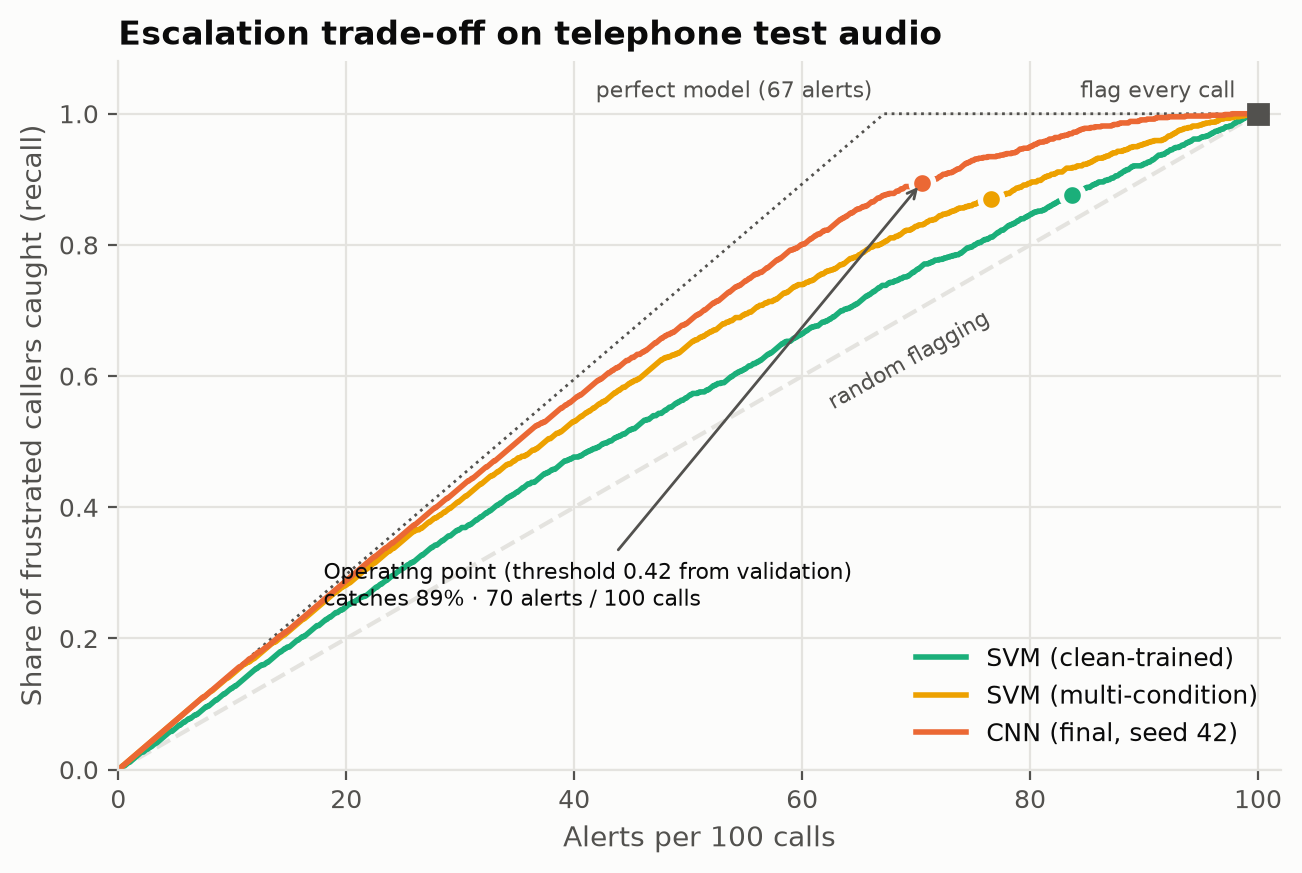

In [16]:
from baseline import ESC_IDX
probs = np.load(RESULTS / "test_probabilities.npz")
y_esc = np.isin(probs["labels"], ESC_IDX)
rows = {}
for key, name in [("svm", "SVM (clean-trained)"), ("svm_mc", "SVM (multi-condition)"), ("cnn_s42", "CNN (final)")]:
    order = np.argsort(-probs[f"{key}_phone"][:, ESC_IDX].sum(1))
    rows[name] = {f"top {k} of 100": y_esc[order[: len(order) * k // 100]].mean() for k in (10, 20, 30, 50)}
display(Markdown("**Prioritised QA review: precision when only the highest-scoring calls are reviewed (phone)**"))
display(pd.DataFrame(rows).T.round(2))
show("12_escalation_tradeoff_test_phone.png", 750)

**What the baselines rely on: grouped permutation importance** (shuffle a whole feature family on the clean
validation set and measure the macro-F1 drop).

model,rf,svm
family,,
MFCC std,0.034,0.135
MFCC delta-deltas (ΔΔ),0.028,0.111
MFCC means,0.038,0.103
MFCC deltas (Δ),0.044,0.092
Spectral shape,0.010,0.030
Voicing,0.013,0.028
Energy (RMS),0.003,0.017
Pitch F0,0.018,0.016
Zero-crossing rate,-0.000,0.012


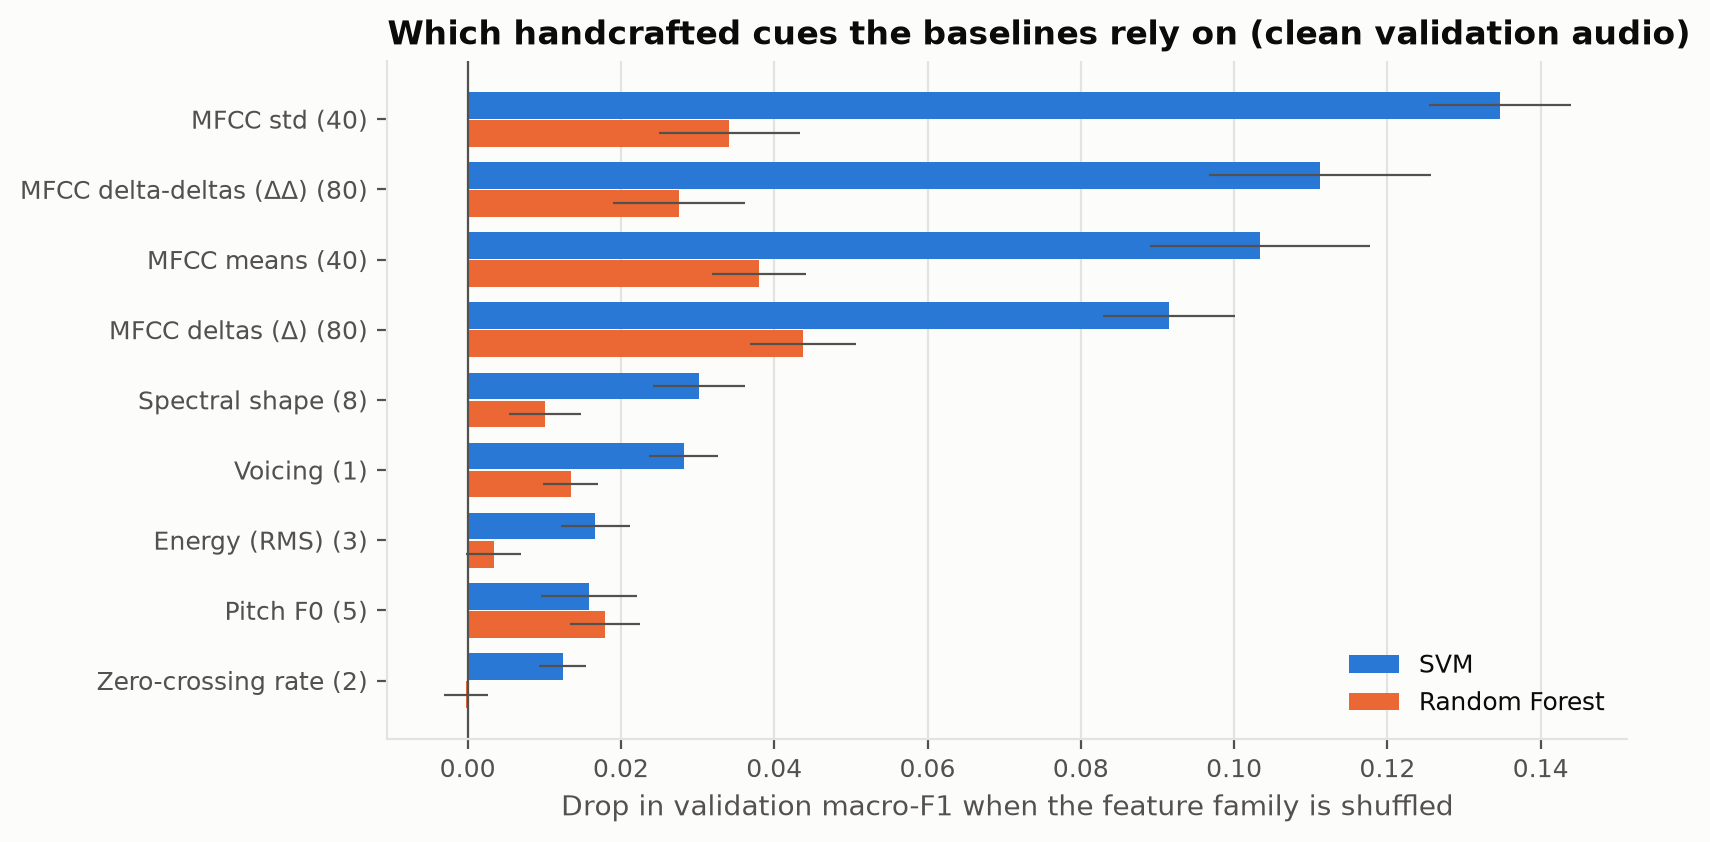

In [17]:
import importance

if RUN_ALL:
    importance.main()

imp = pd.read_csv(RESULTS / "feature_importance.csv")
display(imp.pivot(index="family", columns="model", values="f1_drop_mean").sort_values("svm", ascending=False).round(3))
show("13_feature_importance.png", 800)

**Observations**
* With the validation-chosen threshold, the CNN catches **90% of frustrated callers on phone audio**, and **85% of
  its alerts are correct** (flagging every call: 67%).
* **False alerts fall from 32.8 to 10.5 per 100 calls (−68%)** compared with flagging every call.
* For a QA team with limited capacity, reviewing only the 20 highest-scoring calls out of 100 gives **97%
  genuinely negative calls** (clean-trained SVM: 83%).
* The baselines rely mostly on MFCC statistics (0.09–0.13 macro-F1 each). Pitch, energy and spectral cues add
  little on their own because they are correlated with the MFCCs, so these importances are lower bounds.

<a id="10"></a>
## 10. Demo: predicting on new audio

`src/predict.py` scores any `.wav` file:

```bash
python src/predict.py my_clip.wav            # emotion + escalation decision
python src/predict.py my_call.wav --phone --plot   # long audio: sliding windows + timeline PNG
```

* **Short clips (≤ 3 s):** exactly the training pre-processing, then the predicted emotion and an ESCALATE / OK
  decision.
* **Long audio:** 3 s windows every 1.5 s; an energy-based voice activity detector skips silent windows; the call is
  flagged when two consecutive speech windows (about 4.5 s) average at or above the threshold.

The demo uses **test speaker CRE_1001** (the first test speaker in sorted order, not hand-picked), whom the model
never heard during training.

In [18]:
import make_demo
from predict import predict_file

if RUN_ALL:
    make_demo.main()

DEMO = RESULTS / "demo"
for emotion in ("neutral", "angry"):
    f = DEMO / f"single_{emotion}_CRE_1001.wav"
    print(f"\n=== True emotion: {emotion.upper()} ===")
    display(Audio(filename=str(f)))
    for phone in (False, True):
        predict_file(f, phone=phone)


=== True emotion: NEUTRAL ===


File: single_neutral_CRE_1001.wav  (2.6 s, telephone channel: off)


Emotion probabilities: neutral 0.46  happy 0.37  fear 0.09  sad 0.05  disgust 0.02  angry 0.01
Predicted emotion: NEUTRAL | P(escalate) 0.17 | Decision: OK (threshold 0.42)
File: single_neutral_CRE_1001.wav  (2.6 s, telephone channel: on)
Emotion probabilities: neutral 0.63  happy 0.24  sad 0.04  fear 0.04  disgust 0.03  angry 0.02
Predicted emotion: NEUTRAL | P(escalate) 0.13 | Decision: OK (threshold 0.42)

=== True emotion: ANGRY ===


File: single_angry_CRE_1001.wav  (2.3 s, telephone channel: off)
Emotion probabilities: angry 0.70  disgust 0.27  happy 0.02  neutral 0.01  fear 0.00  sad 0.00
Predicted emotion: ANGRY | P(escalate) 0.97 | Decision: ESCALATE (threshold 0.42)
File: single_angry_CRE_1001.wav  (2.3 s, telephone channel: on)
Emotion probabilities: angry 0.47  disgust 0.47  happy 0.04  neutral 0.01  fear 0.01  sad 0.01
Predicted emotion: ANGRY | P(escalate) 0.95 | Decision: ESCALATE (threshold 0.42)


Simulated call (14.7 s): neutral → neutral → neutral → disgust → angry → angry → angry


File: simulated_call.wav  (14.7 s, telephone channel: on)


  Window  Emotion  P(escalate)
0:00.0  neutral  0.09
0:01.5  neutral  0.48  <
0:03.0  neutral  0.42  <
0:04.5  happy    0.35
0:06.0  happy    0.23
0:07.5  angry    0.87  <
0:09.0  disgust  0.73  <
0:10.5  happy    0.57  <
0:11.7  disgust  0.97  <
Call verdict: ESCALATE (peak 2-window score 0.80 at 0:07.5-0:12.0, threshold 0.42)


Timeline saved: results/demo/simulated_call_phone_timeline.png


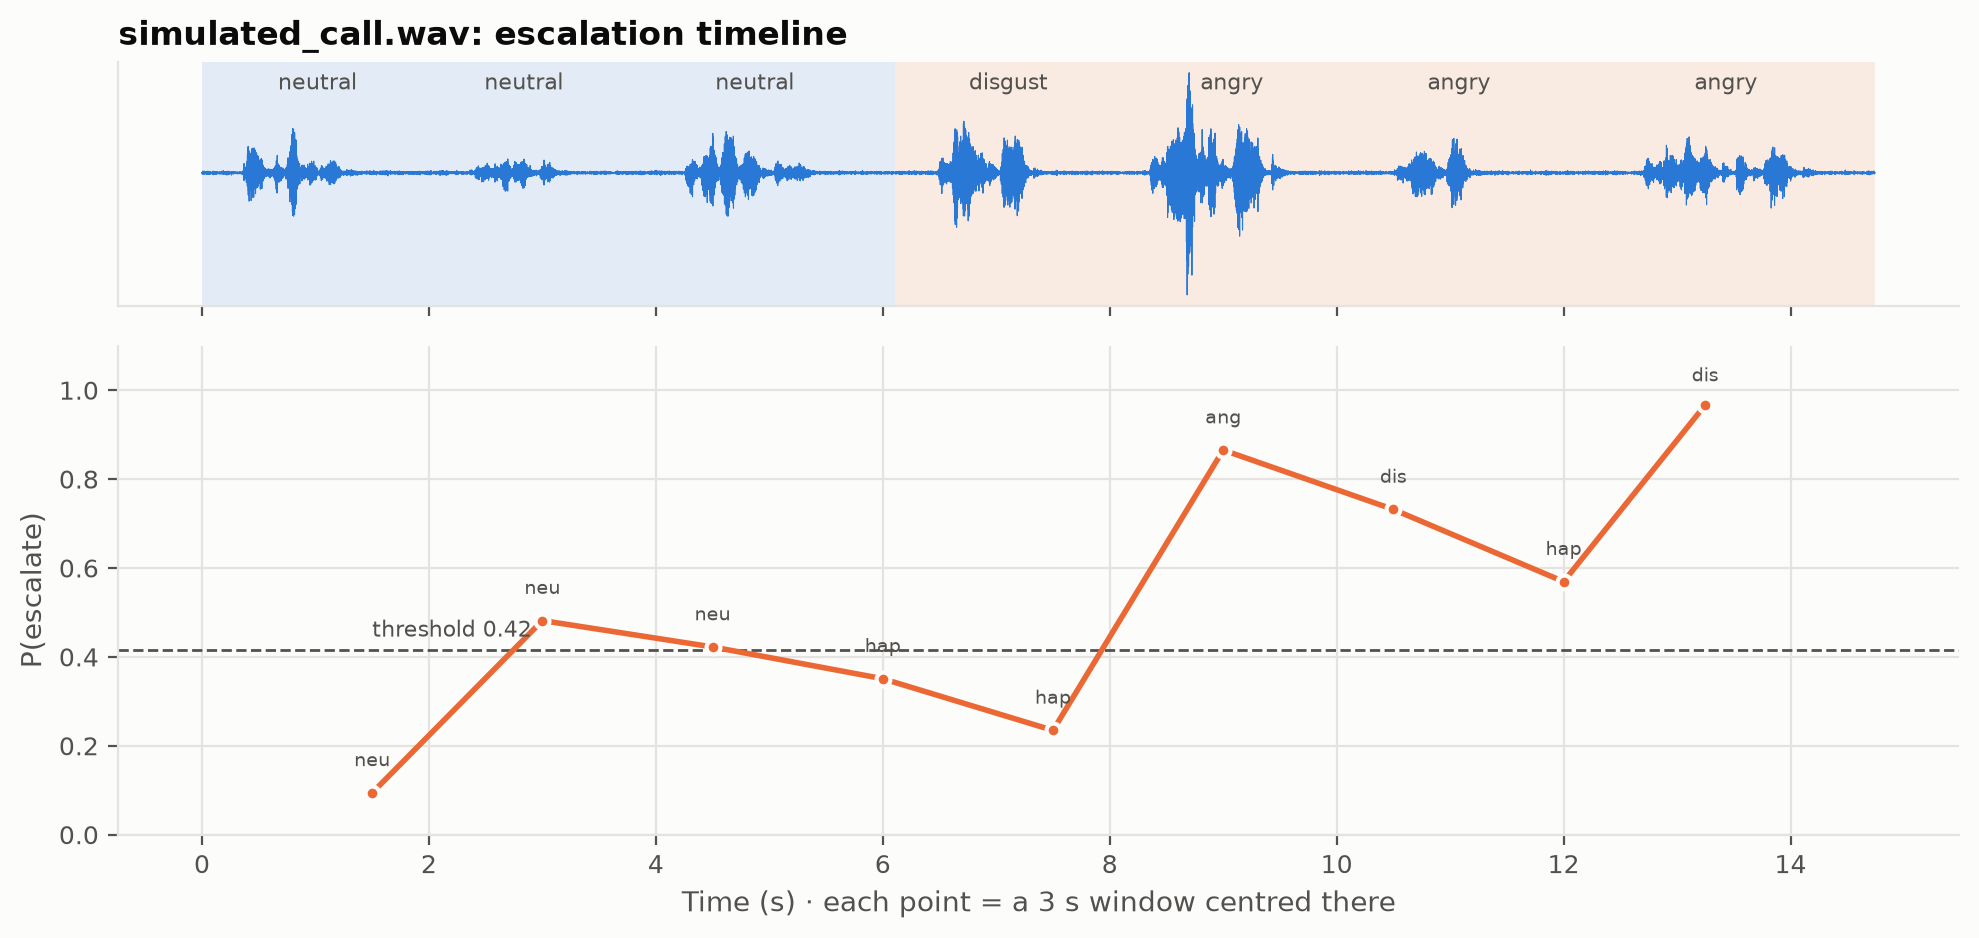

In [19]:
truth = pd.read_csv(DEMO / "simulated_call_truth.csv")
print("Simulated call (14.7 s): " + " → ".join(truth.emotion))
display(Audio(filename=str(DEMO / "simulated_call.wav")))
_ = predict_file(DEMO / "simulated_call.wav", phone=True, plot=True, truth=truth)
display(Image(filename=str(DEMO / "simulated_call_phone_timeline.png"), width=1000))

**Observations**
* Single clips are classified correctly on both channels (neutral → OK, angry → ESCALATE with P ≈ 0.95).
* The simulated call is flagged **ESCALATE at 0:07.5–0:12.0**, where the anger starts.
* The demo also shows the known weaknesses honestly: one low-intensity angry take is heard as *happy*; the disgust
  clip is missed; and on phone audio two neutral windows score just above the 0.42 threshold. That threshold was
  tuned for single clips; a call-level threshold should be tuned on whole calls.

<a id="11"></a>
## 11. Conclusions, limitations and next steps

### Conclusions
1. A CNN on log-mel spectrograms, trained with telephone-channel and noise augmentation, recognises six emotions from
   **unseen speakers** with **macro-F1 0.65 (clean) and 0.64 (phone)**, about 3.8× chance.
2. For the business decision it catches **90% of frustrated callers** with **85% precision on telephone audio**,
   cutting false alerts by 68% compared with flagging every call.
3. **Matching the training data to the deployment channel matters most:** a model trained on clean audio collapses
   on phone calls (macro-F1 0.54 → 0.21). Multi-condition training recovers most of this, and the CNN adds a further
   +0.12.

### Limitations (gap to a production system)
* **Acted vs real emotion:** CREMA-D and RAVDESS are actors reading fixed sentences. Real customer frustration is
  subtler, mixed, and builds over a conversation.
* **Simulated channel:** real calls use other codecs (Opus, AMR, G.729), packet loss, echo and background noise.
* **No speaker diarisation:** real recordings contain agent and customer; only the customer should be scored.
* **Emotion is not intent:** "I want to close my account", said calmly, is still an escalation; the words matter as
  well as the tone.
* **Thresholds:** tuned on clip-level validation data. Call-level thresholds and probability calibration need real
  call data.

### Next steps before real-world use
1. **Validate on authorised, anonymised real support recordings** (the single most important step).
2. Add **speaker diarisation** and **voice activity detection** for full calls.
3. **Fine-tune** on in-domain data, using pre-trained speech models (for example wav2vec 2.0 or WavLM) as encoders.
4. **Combine tone with words:** speech-to-text plus text sentiment.
5. Deploy as **decision support with a human in the loop**, with monitoring for drift and bias, and compliance with
   data-protection rules (PII redaction, consent, data residency).
6. **Edge deployment** on a Raspberry Pi 5 with ONNX Runtime: on-device inference, so audio never leaves the device.